In [1]:
# HyLANET-X revision: leakage-controlled experiments

This notebook produces the numbers, tables and figures for the revised manuscript.

**Running it**

Run the cells from top to bottom. The first cell installs anything missing, and from then on every cell prints a line when it finishes (or the error if it fails). Long steps show progress bars. Deep models use PyTorch and run on the GPU when one is available, with TF32 maths on A100/H100. With several GPUs, several runs are trained at the same time (one per GPU, see section 3). Trees and the SVM run on the CPU.

**Protocol**

- Each dataset is cleaned once. Exact duplicates, feature vectors with conflicting labels and very rare classes are removed, and an optional per-class cap is applied with a fixed seed. Every step is logged with row counts.
- Splits are 60% train, 15% validation and 25% test. There are two protocols: stratified random splits (five seeds) and a time-ordered split within each class (one fixed split, five model seeds). The time-ordered split is used only for datasets that have timestamps.
- All preprocessing (imputation, encoding, scaling, PCA) is fitted on the training split only.
- Hyperparameters, early stopping, the learning-rate schedule and the fusion weight α are chosen on the validation split only. The test split is scored once.
- Every run is cached to disk, so after a disconnect the notebook can be re-run and continues where it stopped.

**Data**

By default the datasets are downloaded with `kagglehub` (section 0). To use local copies, set `USE_KAGGLEHUB = False` and point `DATA_DIR` to them. Folders are searched recursively for `.csv` and `.parquet` files.

| Dataset | Kaggle source | Format | Notes | Original source |
|---|---|---|---|---|
| CICIDS2017 | `dhoogla/cicids2017` | parquet | cleaned release without metadata columns (no IPs, no timestamps), so only the random protocol is run. The original CIC `GeneratedLabelledFlows` CSVs also work and do have timestamps | https://www.unb.ca/cic/datasets/ids-2017.html |
| TON_IoT | `arnobbhowmik/ton-iot-network-dataset` | csv | `train_test_network.csv`, no `ts` column, so only the random protocol is run | https://research.unsw.edu.au/projects/toniot-datasets |
| IoTID20 | `rohulaminlabid/iotid20-dataset` | csv | has timestamps | https://sites.google.com/view/iot-network-intrusion-dataset |
| SCADANet | `ealgul/scada-dataset-v01` | csv | check the detected label and time columns in the printout | Algül et al., Computer Networks 278 (2026) 112087 |

**Models**

| Name | Input | Role |
|---|---|---|
| RF, LGBM, SVM (linear), MLP | standardized features | baselines |
| CNN-BiLSTM-Tr | PCA components | deep stage of the first submission (rebuilt in PyTorch), kept as a baseline |
| FTA | standardized features | order-free deep branch: each feature becomes a token, self-attention without positional encoding |
| HyLANET-X | LGBM + FTA | soft voting, α chosen on validation over [0, 1] |
| HyLANET-X (stacked) | LGBM + FTA | logistic-regression combiner fitted on validation |
| HyLANET-X (original design) | LGBM on PCA + CNN-BiLSTM-Tr | the submitted architecture, now with validation-only selection |
| RF+LGBM | RF + LGBM | tree-only fusion, a control for "is any gain just ensembling?" |

SyntaxError: invalid decimal literal (157666238.py, line 23)

In [17]:
# Installs what is missing. Requirements that are already met are left alone, so a CUDA build of
# PyTorch that came with the machine is never replaced.
import importlib.util, subprocess, sys, time

REQUIREMENTS = ["numpy", "pandas>=2.0", "scipy>=1.11", "scikit-learn>=1.3", "lightgbm>=4.0",
                "optuna>=3.4", "matplotlib", "joblib", "pyarrow", "kagglehub", "tqdm",
                "ipywidgets", "jinja2", "psutil"]
if importlib.util.find_spec("torch") is None:
    REQUIREMENTS.append("torch")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", *REQUIREMENTS], check=True)

from IPython import get_ipython


def _register_cell_status():
    ip = get_ipython()
    if ip is None or getattr(ip, "_cell_status_registered", False):
        return
    state = {"t0": None}

    def pre(*args, **kwargs):
        state["t0"] = time.time()

    def post(result):
        if state["t0"] is None:
            return
        dt = time.time() - state["t0"]
        took = f"{dt:.1f} s" if dt < 120 else f"{dt / 60:.1f} min"
        err = result.error_in_exec or result.error_before_exec
        if err is not None:
            print(f"\n✗ Cell failed after {took}: {type(err).__name__}: {err}")
        else:
            print(f"\n✓ Cell ran successfully ({took})")

    ip.events.register("pre_run_cell", pre)
    ip.events.register("post_run_cell", post)
    ip._cell_status_registered = True


_register_cell_status()
print("Packages ready. From the next cell on, each cell reports when it finishes.")

Packages ready. From the next cell on, each cell reports when it finishes.

✓ Cell ran successfully (0.6 s)



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [18]:
import os, gc, re, json, glob, math, time, copy, random, platform, tempfile, warnings, traceback
import threading, queue, faulthandler
from concurrent.futures import ThreadPoolExecutor, as_completed
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy import stats
from IPython.display import display
from tqdm.auto import tqdm

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix, precision_recall_fscore_support)
import lightgbm as lgb
import optuna
import psutil

import torch
import torch.nn as nn
import torch.nn.functional as F

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    # TF32 matrix maths on Ampere and Hopper GPUs (A100, H100)
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True


N_GPUS = torch.cuda.device_count()

# Each worker thread has its own GPU, its own share of CPU cores and a "quiet" flag that turns off
# the inner progress bars when several runs print at the same time.
_worker = threading.local()
_SEED_LOCK = threading.Lock()
_LOG_LOCK = threading.Lock()
# LightGBM uses OpenMP; two LightGBM models training or predicting at the same time in one process
# can crash the kernel. Every LightGBM call takes this lock, so only one runs at a time.
# Random Forest, the SVM and the PyTorch models in other workers keep running meanwhile.
_LGBM_LOCK = threading.Lock()


def set_worker(device, jobs, quiet_mode):
    _worker.device, _worker.jobs, _worker.quiet = device, jobs, quiet_mode


def current_device():
    return getattr(_worker, "device", DEVICE)


def cpu_jobs():
    return getattr(_worker, "jobs", -1)


def quiet():
    return getattr(_worker, "quiet", False)


def set_seed(seed, device=None):
    # Seeds only the CPU generator and the generator of this worker's GPU, so seeding one run
    # never disturbs a run that is training on another GPU at the same time.
    random.seed(seed)
    np.random.seed(seed)
    torch.default_generator.manual_seed(seed)
    if device is not None and device.type == "cuda":
        with torch.cuda.device(device):
            torch.cuda.manual_seed(seed)


def ram_used():
    return f"{psutil.Process().memory_info().rss / 2**30:.1f} GB used of {psutil.virtual_memory().total / 2**30:.0f} GB"


def free_memory():
    gc.collect()
    dev = current_device()
    if dev.type == "cuda":
        with torch.cuda.device(dev):
            torch.cuda.empty_cache()


plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10,
                     "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
print("lightgbm", lgb.__version__, "| optuna", optuna.__version__, "| torch", torch.__version__)
if DEVICE.type == "cuda":
    for i in range(N_GPUS):
        props = torch.cuda.get_device_properties(i)
        print(f"GPU {i}: {props.name}, {props.total_memory / 2**30:.0f} GB")
else:
    print("GPU: none, deep models will run on the CPU")
print("CPU threads:", os.cpu_count())

numpy 2.2.6 | pandas 2.3.3 | scikit-learn 1.7.2
lightgbm 4.7.0 | optuna 5.0.0 | torch 2.11.0+cu130
GPU 0: NVIDIA L4, 22 GB
GPU 1: NVIDIA L4, 22 GB
CPU threads: 256

✓ Cell ran successfully (0.0 s)


## 0. Configuration

Change paths here. Delete `OUT_DIR` (or point it somewhere new) whenever you change anything that affects the data, such as caps or class rules, because splits and runs are cached.

In [19]:
USE_KAGGLEHUB = True                        # download the four datasets with kagglehub (section 0b)
DATA_DIR = os.path.abspath("data")          # used only when USE_KAGGLEHUB is False
OUT_DIR = os.path.abspath("hylanet_outputs_v2")  # created next to the notebook (v2: fixed SCADANet cleaning)

DATASETS = {
    "CICIDS2017": {"enabled": True, "path": f"{DATA_DIR}/CICIDS2017"},
    "TON_IoT":    {"enabled": True, "path": f"{DATA_DIR}/TON_IoT/train_test_network.csv"},
    "IoTID20":    {"enabled": True, "path": f"{DATA_DIR}/IoTID20/IoT Network Intrusion Dataset.csv"},
    "SCADANet":   {"enabled": True, "path": f"{DATA_DIR}/SCADANet"},
    # The 56,661-row CICIDS2017 subset used in the first submission. Off by default.
    # Turn it on only to show how that subset behaves under the new protocol.
    "CICIDS2017_legacy": {"enabled": False, "path": f"{DATA_DIR}/legacy/CICIDS2017.csv"},
}

SEEDS = [42, 123, 2024, 3407, 7777]
EXTRA_SEEDS = [42, 123, 2024]       # raw-vs-PCA, order-permutation and transfer studies
TUNE_SEED = 42
DATA_SEED = 0                       # used only for the per-class cap and tuning subsamples

SPLIT = (0.60, 0.15, 0.25)          # train / validation / test
PURGE_FRAC = 0.005                  # share of each class dropped at each time boundary
MIN_CLASS_COUNT = 50                # classes with fewer rows after cleaning are removed (and reported)
MAX_PER_CLASS = {"CICIDS2017": 100_000, "TON_IoT": None, "IoTID20": 100_000,
                 "SCADANet": 100_000, "CICIDS2017_legacy": None}
PCA_VAR = 0.95
CLIP_VALUE = 1e6
CAT_MAX_LEVELS = 50                 # a text column keeps its 50 most frequent values (on train); the rest become "other"
FREE_TEXT_MAX_LEVELS = 1000         # text columns with more distinct values are free text (payloads, URIs) and are dropped
ALPHAS = np.round(np.arange(0.0, 1.0001, 0.05), 2)

N_TRIALS = {"rf": 20, "lgbm": 30, "svm": 5, "mlp": 8, "cnn": 6, "fta": 10}
TUNE_MAX_TRAIN = 120_000
TUNE_MAX_VAL = 40_000
TUNE_MAX_TRAIN_SVM = 40_000         # the linear SVM is slow to fit and is only a reference baseline
TUNE_EPOCHS = 12
MAX_EPOCHS = 60
BATCH_SIZE = 512
PATIENCE = 8                        # epochs without a better validation macro-F1 before stopping
DL_INPUT_CLIP = 50.0                # standardized inputs to the deep models are clipped to +/- this
LATENCY_RUNS = 300
# 1 = one run after another in the main process (the stable setting; trees use every CPU core).
# Set to the number of GPUs to train several runs at once. Use this only after a FAST run has
# finished cleanly with 1, because LightGBM, Random Forest and PyTorch then share one process.
PARALLEL_WORKERS = 2
SHOW_CONFUSION_FIGURES = False
CACHE_DATA = True                   # cleaned datasets are saved, so a kernel restart does not redo loading
CACHE_VERSION = 4                   # raise this when the cleaning code changes; older caches are rebuilt      # confusion matrices are always saved; showing all of them is slow

RUN = {"tune": True, "random": True, "temporal": True, "raw_vs_pca": True,
       "permutation": True, "efficiency": True, "transfer": True}

FAST = False                        # quick end-to-end check with tiny budgets
if FAST:
    SEEDS, EXTRA_SEEDS = [42], [42]
    N_TRIALS = {k: 2 for k in N_TRIALS}
    MAX_EPOCHS, TUNE_EPOCHS = 4, 2
    MAX_PER_CLASS = {k: 3000 for k in MAX_PER_CLASS}
    OUT_DIR = OUT_DIR + "_fast"

for sub in ("splits", "tuning", "runs", "preds", "probs", "tables", "figures",
            "figures/confusion", "transfer", "data_cache"):
    os.makedirs(os.path.join(OUT_DIR, sub), exist_ok=True)

# If the kernel dies inside compiled code (LightGBM, PyTorch, BLAS), the Python stack of every
# thread at that moment is written here. Send the end of this file when reporting a crash.
_crash_file = open(os.path.join(OUT_DIR, "crash_trace.log"), "a")
_crash_file.write(f"\n===== session started {time.strftime('%Y-%m-%d %H:%M:%S')} =====\n")
_crash_file.flush()
faulthandler.enable(file=_crash_file, all_threads=True)


def _gpu_names():
    if not torch.cuda.is_available():
        return []
    return [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())]


ENV = {"python": platform.python_version(), "platform": platform.platform(),
       "processor": platform.processor(), "cpu_count": os.cpu_count(), "gpus": _gpu_names(),
       "numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
       "lightgbm": lgb.__version__, "optuna": optuna.__version__,
       "torch": torch.__version__, "cuda": torch.version.cuda, "parallel_workers": PARALLEL_WORKERS}
with open(os.path.join(OUT_DIR, "environment.json"), "w") as fh:
    json.dump(ENV, fh, indent=2)
ENV

{'python': '3.10.20',
 'platform': 'Linux-6.8.0-110-generic-x86_64-with-glibc2.35',
 'processor': 'x86_64',
 'cpu_count': 256,
 'gpus': ['NVIDIA L4', 'NVIDIA L4'],
 'numpy': '2.2.6',
 'pandas': '2.3.3',
 'scikit-learn': '1.7.2',
 'lightgbm': '4.7.0',
 'optuna': '5.0.0',
 'torch': '2.11.0+cu130',
 'cuda': '13.0',
 'parallel_workers': 2}


✓ Cell ran successfully (0.0 s)


### 0b. Download the datasets

Public Kaggle datasets download without an API key. The files are cached, so later runs reuse them.

In [20]:
KAGGLE_SOURCES = {
    "CICIDS2017": "dhoogla/cicids2017",
    "TON_IoT": "arnobbhowmik/ton-iot-network-dataset",
    "IoTID20": "rohulaminlabid/iotid20-dataset",
    "SCADANet": "ealgul/scada-dataset-v01",
}

if USE_KAGGLEHUB:
    import kagglehub
    for name, handle in KAGGLE_SOURCES.items():
        if not DATASETS.get(name, {}).get("enabled", False):
            continue
        try:
            path = kagglehub.dataset_download(handle)
        except Exception as e:
            raise RuntimeError(
                f"Download of {handle} failed: {e}\nIf Kaggle asks for a login, set KAGGLE_USERNAME and "
                "KAGGLE_KEY (kaggle.com > Settings > API > Create new token) and run this cell again.") from e
        DATASETS[name]["path"] = path
        files = [f for f in sorted(glob.glob(os.path.join(path, "**", "*"), recursive=True)) if os.path.isfile(f)]
        print(f"{name}: {handle} -> {path} ({len(files)} files)")
        for f in files[:25]:
            print(f"    {os.path.relpath(f, path)}  ({os.path.getsize(f) / 2**20:.1f} MB)")
else:
    for name, cfg in DATASETS.items():
        if cfg["enabled"]:
            print(f"{name}: {cfg['path']} ({'found' if os.path.exists(cfg['path']) else 'NOT FOUND'})")

CICIDS2017: dhoogla/cicids2017 -> /home/.cache/kagglehub/datasets/dhoogla/cicids2017/versions/3 (8 files)
    Benign-Monday-no-metadata.parquet  (54.1 MB)
    Botnet-Friday-no-metadata.parquet  (18.9 MB)
    Bruteforce-Tuesday-no-metadata.parquet  (44.0 MB)
    DDoS-Friday-no-metadata.parquet  (24.1 MB)
    DoS-Wednesday-no-metadata.parquet  (65.0 MB)
    Infiltration-Thursday-no-metadata.parquet  (22.1 MB)
    Portscan-Friday-no-metadata.parquet  (13.0 MB)
    WebAttacks-Thursday-no-metadata.parquet  (16.8 MB)
TON_IoT: arnobbhowmik/ton-iot-network-dataset -> /home/.cache/kagglehub/datasets/arnobbhowmik/ton-iot-network-dataset/versions/1 (1 files)
    train_test_network.csv  (28.5 MB)
IoTID20: rohulaminlabid/iotid20-dataset -> /home/.cache/kagglehub/datasets/rohulaminlabid/iotid20-dataset/versions/2 (2 files)
    IoT Network Intrusion Dataset.csv  (294.2 MB)
    archive (3)/cybersecurity_attacks.csv  (16.9 MB)
SCADANet: ealgul/scada-dataset-v01 -> /home/.cache/kagglehub/datasets/ealgul

In [21]:
def to_jsonable(o):
    if isinstance(o, dict):
        return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_jsonable(v) for v in o]
    if isinstance(o, np.ndarray):
        return to_jsonable(o.tolist())
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating, float)):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    return o


def save_json(obj, path):
    with open(path, "w") as fh:
        json.dump(to_jsonable(obj), fh, indent=1)


def load_json(path):
    with open(path) as fh:
        return json.load(fh)


def safe_key(name):
    return re.sub(r"[^A-Za-z0-9]+", "_", name).strip("_")


def save_table(df, name, index=False):
    df.to_csv(os.path.join(OUT_DIR, "tables", f"{name}.csv"), index=index)
    try:
        df.to_latex(os.path.join(OUT_DIR, "tables", f"{name}.tex"), index=index, escape=True)
    except Exception as e:
        print("  (LaTeX export skipped:", e, ")")
    print(f"[table] {name}")
    display(df)


def save_fig(fig, name, sub="figures"):
    for ext in ("pdf", "png"):
        fig.savefig(os.path.join(OUT_DIR, sub, f"{name}.{ext}"), bbox_inches="tight")
    plt.show()
    plt.close(fig)


class Audit:
    def __init__(self, name):
        self.name, self.rows = name, []

    def log(self, step, data, note=""):
        n = data if isinstance(data, (int, np.integer)) else len(data)
        self.rows.append({"dataset": self.name, "step": step, "rows": int(n), "note": note})
        print(f"  {step}: {int(n):,} {note}")

    def frame(self):
        return pd.DataFrame(self.rows)


✓ Cell ran successfully (0.0 s)


## 1. Loading and cleaning

Each loader returns one frame with the features plus reserved columns: `__y` (class name), `__ybin` (0 = normal, 1 = attack), `__ts` (seconds, NaN when not available) and `__id_*` (identifier columns kept aside for the shortcut check). Identifiers such as IP addresses, source ports, flow IDs and raw timestamps are never used as features. Text columns with more than `FREE_TEXT_MAX_LEVELS` distinct values (payloads, URIs, packet summaries) are removed before cleaning; other text columns are kept as categories, with their `CAT_MAX_LEVELS` most frequent training values. Time deltas and durations are kept as features; only absolute timestamps are set aside. A note is printed for any class that loses more than 90% of its rows in cleaning. If a dataset folder has several files with different columns, the loader picks the right file instead of stacking them. Cleaned datasets are cached in `OUT_DIR/data_cache`, so after a kernel restart this cell takes seconds. Delete that folder if you change any cleaning setting.

In [22]:
def list_data_files(path):
    # All .parquet and .csv files under a folder (or the file itself). If a folder holds both
    # formats, only the parquet files are used, because they are the cleaned copies.
    if os.path.isdir(path):
        pq = sorted(glob.glob(os.path.join(path, "**", "*.parquet"), recursive=True))
        csv = sorted(glob.glob(os.path.join(path, "**", "*.csv"), recursive=True))
        if pq and csv:
            print(f"  {len(pq)} parquet and {len(csv)} csv files found: using the parquet files")
        files = pq or csv
    else:
        files = [path] if os.path.exists(path) else []
    if not files:
        raise FileNotFoundError(f"no CSV or parquet files at {path}")
    return files


def read_csv_any(f):
    try:
        d = pd.read_csv(f, low_memory=False)
    except UnicodeDecodeError:
        d = pd.read_csv(f, low_memory=False, encoding="latin-1")
    d.columns = [str(c).strip().lstrip("\ufeff") for c in d.columns]
    return d


def read_any(f):
    if f.lower().endswith(".parquet"):
        d = pd.read_parquet(f)
        d.columns = [str(c).strip() for c in d.columns]
        return d
    return read_csv_any(f)


def read_many(files, name):
    # Reads several files of one dataset and refuses to stack files whose columns differ,
    # because that silently creates empty columns and mixes different versions of a dataset.
    parts, first = [], None
    for f in tqdm(files, desc=f"{name} files", leave=False):
        d = read_any(f)
        tqdm.write(f"  read {os.path.basename(f)}: {len(d):,} rows x {d.shape[1]} columns")
        if first is None:
            first = (f, set(d.columns))
        elif set(d.columns) != first[1]:
            raise ValueError(f"{os.path.basename(f)} and {os.path.basename(first[0])} have different columns. "
                             f"Point DATASETS['{name}']['path'] at the file you want to use.")
        parts.append(d)
    return pd.concat(parts, ignore_index=True) if len(parts) > 1 else parts[0]


def pick_file(files, must_have, prefer=None):
    # Chooses the file that has the needed columns; prefers a name match, otherwise the largest file.
    ok = []
    for f in files:
        cols = set(c.strip() for c in read_any_header(f))
        if all(any(m.lower() == c.lower() for c in cols) for m in must_have):
            ok.append(f)
    if not ok:
        raise ValueError(f"no file has the columns {must_have}: {[os.path.basename(f) for f in files]}")
    named = [f for f in ok if prefer and prefer.lower() in os.path.basename(f).lower()]
    chosen = named[0] if named else max(ok, key=os.path.getsize)
    others = [os.path.basename(f) for f in files if f != chosen]
    print(f"  using {os.path.basename(chosen)}" + (f" (ignored: {others})" if others else ""))
    return chosen


def read_any_header(f):
    if f.lower().endswith(".parquet"):
        import pyarrow.parquet as pq
        return pq.read_schema(f).names
    try:
        return list(pd.read_csv(f, nrows=0).columns)
    except UnicodeDecodeError:
        return list(pd.read_csv(f, nrows=0, encoding="latin-1").columns)


def step(msg):
    # Printed and written to OUT_DIR/load_progress.log straight away, so the last step before a
    # crash is always visible, even if the notebook output is lost.
    line = f"{time.strftime('%H:%M:%S')} {msg}"
    print(line, flush=True)
    with open(os.path.join(OUT_DIR, "load_progress.log"), "a") as fh:
        fh.write(line + "\n")


def find_col(cols, candidates):
    low = {c.lower(): c for c in cols}
    for cand in candidates:
        if cand.lower() in low:
            return low[cand.lower()]
    return None


def feature_cols(df):
    return [c for c in df.columns if not c.startswith("__")]


def _to_float(v):
    if isinstance(v, str) and ("_" in v or v.strip().lower() in ("nan", "inf", "-inf", "infinity")):
        return np.nan
    try:
        x = float(v)
    except (TypeError, ValueError, OverflowError):
        return np.nan
    return x if math.isfinite(x) else np.nan


def safe_to_numeric(s):
    # Text to float in plain Python. pandas' compiled parser (pd.to_numeric) can crash the kernel
    # on unusual values such as very long digit strings, so it is not used on raw text columns.
    vals = s.to_numpy(dtype=object)
    return pd.Series(np.fromiter((_to_float(v) for v in vals), dtype=np.float64, count=len(vals)),
                     index=s.index, name=s.name)


def coerce_numeric(df, cols, min_share=0.99, verbose=False):
    # Text columns whose values are almost all numbers become numeric. A sample is checked first.
    for c in cols:
        if df[c].dtype != object:
            continue
        if verbose:
            step(f"    checking text column {c!r}")
        filled = df[c].dropna()
        if len(filled) == 0:
            continue
        sample = filled.sample(min(len(filled), 5000), random_state=0)
        if safe_to_numeric(sample).notna().mean() < min_share:
            continue
        s = safe_to_numeric(df[c])
        if s[df[c].notna()].notna().mean() >= min_share:
            df[c] = s
            if verbose:
                step(f"    {c!r} converted to numbers")
    return df


def slim_text_columns(df, audit):
    # Text columns with more than FREE_TEXT_MAX_LEVELS distinct values are free text (payloads,
    # URIs, packet summaries) and are removed. The others are kept as categories; Prep later keeps
    # their CAT_MAX_LEVELS most frequent values on the training split. No labels are used here.
    dropped, kept = [], []
    for c in feature_cols(df):
        if not pd.api.types.is_numeric_dtype(df[c]):
            (dropped if df[c].nunique(dropna=False) > FREE_TEXT_MAX_LEVELS else kept).append(c)
    if dropped:
        df = df.drop(columns=dropped)
    for c in kept:
        df[c] = pd.Categorical(df[c].astype(str))
    audit.log("text columns", len(kept) + len(dropped),
              f"kept {len(kept)} as categories; removed {len(dropped)} with more than {FREE_TEXT_MAX_LEVELS} "
              f"values: {dropped}" if dropped else f"kept {len(kept)} as categories")
    return df


def to_seconds(series, dayfirst=True):
    t = pd.to_datetime(series.astype(str).str.strip(), dayfirst=dayfirst, errors="coerce",
                       format="mixed", utc=True)
    return (t - pd.Timestamp("1970-01-01", tz="UTC")).dt.total_seconds()


def finalize(name, df, audit):
    df = df[df["__y"].notna() & (df["__y"].astype(str).str.len() > 0)].reset_index(drop=True)
    audit.log("rows with a label", df)
    step(f"  {name}: checking text columns")
    df = slim_text_columns(df, audit)
    gc.collect()
    step(f"  {name}: removing duplicates")
    fc = feature_cols(df)
    num = [c for c in fc if pd.api.types.is_numeric_dtype(df[c])]
    df[num] = df[num].replace([np.inf, -np.inf], np.nan)

    h = pd.util.hash_pandas_object(df[fc], index=False).to_numpy()
    dup = pd.DataFrame({"h": h, "y": df["__y"].to_numpy()}).duplicated().to_numpy()
    df, h = df[~dup].reset_index(drop=True), h[~dup]
    audit.log("after removing exact duplicates", df, f"removed {int(dup.sum()):,}")

    n_labels = pd.Series(df["__y"].to_numpy()).groupby(h).nunique()
    conflict = np.isin(h, n_labels.index[n_labels > 1].to_numpy())
    df = df[~conflict].reset_index(drop=True)
    audit.log("after removing feature vectors with conflicting labels", df,
              f"removed {int(conflict.sum()):,}")

    vc = df["__y"].value_counts()
    rare = vc[vc < MIN_CLASS_COUNT]
    if len(rare):
        df = df[~df["__y"].isin(rare.index)].reset_index(drop=True)
        audit.log(f"after removing classes with fewer than {MIN_CLASS_COUNT} rows", df,
                  "; ".join(f"{k} ({v})" for k, v in rare.items()))

    cap = MAX_PER_CLASS.get(name)
    if cap:
        rng = np.random.RandomState(DATA_SEED)
        labels = df["__y"].to_numpy()
        keep = []
        for c in sorted(pd.unique(labels)):
            idx = np.flatnonzero(labels == c)
            if len(idx) > cap:
                idx = np.sort(rng.choice(idx, cap, replace=False))
            keep.append(idx)
        keep = np.sort(np.concatenate(keep))
        n_before = len(df)
        df = df.iloc[keep].reset_index(drop=True)
        audit.log(f"after per-class cap of {cap:,} (seed {DATA_SEED})", df,
                  f"removed {n_before - len(df):,}")
    for c in [c for c in df.columns if c.startswith("__id_")]:
        df[c] = pd.Categorical(df[c].astype(str))
    return df


def report_class_losses(name, before, after):
    # Duplicate removal can shrink a class a lot (identical packets in a flood). A class that loses
    # almost everything is reported, because it changes what the dataset can show.
    for c, n0 in before.items():
        n1 = int(after.get(c, 0))
        if n0 and n1 / n0 < 0.10:
            print(f"  NOTE {name}: class {c!r} kept {n1:,} of {int(n0):,} rows ({100 * n1 / n0:.1f}%) after cleaning")


def package(name, df):
    le = LabelEncoder().fit(df["__y"].astype(str))
    ts = None
    if "__ts" in df.columns:
        t = pd.to_numeric(df["__ts"], errors="coerce").to_numpy(dtype=float)
        if np.isfinite(t).mean() >= 0.99:
            ts = t
    X = df[feature_cols(df)]
    X = X.astype({c: np.float32 for c in X.columns if pd.api.types.is_numeric_dtype(X[c])})
    return {"name": name,
            "X": X,
            "y": le.transform(df["__y"].astype(str)).astype(np.int32),
            "y_bin": df["__ybin"].to_numpy(dtype=np.int32),
            "ts": ts,
            "ids": df[[c for c in df.columns if c.startswith("__id_")]],
            "classes": [str(c) for c in le.classes_],
            "K": len(le.classes_)}


✓ Cell ran successfully (0.0 s)


In [23]:
# CICIDS2017 (original CIC release). 15 labels are mapped to 6 classes, as in the first submission.
# Infiltration (36 flows) and Heartbleed (11 flows) are too small to evaluate and are removed.
# Keys are lower-case with punctuation removed, so "DoS Hulk", "DOS_HULK" and "dos-hulk" all match.
CIC_MAP = {"benign": "BENIGN", "ddos": "DoS", "doshulk": "DoS", "dosgoldeneye": "DoS",
           "dosslowloris": "DoS", "dosslowhttptest": "DoS", "portscan": "PortScan",
           "ftppatator": "BruteForce", "sshpatator": "BruteForce", "bot": "Bot", "botnet": "Bot",
           "dos": "DoS", "bruteforce": "BruteForce",
           "infiltration": None, "heartbleed": None}
CIC_ID_COLS = ["Flow ID", "Source IP", "Source Port", "Destination IP"]


def map_cic_label(v):
    k = re.sub(r"[^a-z0-9]", "", str(v).lower())
    if k.startswith("webattack"):
        return "WebAttack"
    return CIC_MAP.get(k, "__unknown__")


def cic_time(series):
    t = pd.to_datetime(series.astype(str).str.strip(), dayfirst=True, errors="coerce", format="mixed")
    # Capture ran from about 08:00 to 17:00. Several files write afternoon times without AM/PM
    # (for example 1:30 for 13:30), so hours below 8 are moved to the afternoon.
    t = t.where(~(t.dt.hour < 8), t + pd.Timedelta(hours=12))
    return (t - pd.Timestamp("1970-01-01")).dt.total_seconds()


def load_cicids2017(path, audit):
    files = list_data_files(path)
    parts, n_raw, n_empty, removed = [], 0, 0, {}
    for f in tqdm(files, desc="CICIDS2017 files", leave=False):
        d = read_any(f)
        n_raw += len(d)
        lab_col = find_col(d.columns, ["Label"])
        if lab_col is None:
            raise ValueError(f"no Label column in {f}")
        if lab_col != "Label":
            d = d.rename(columns={lab_col: "Label"})
        n0 = len(d)
        d = d.dropna(subset=["Label"])
        n_empty += n0 - len(d)
        lab = d["Label"].map(map_cic_label)
        bad = lab.isna() | (lab == "__unknown__")
        for k, v in d.loc[bad, "Label"].astype(str).str.strip().value_counts().items():
            removed[k] = removed.get(k, 0) + int(v)
        unknown = sorted(d.loc[lab == "__unknown__", "Label"].astype(str).unique())
        if unknown:
            print(f"  WARNING: labels not in CIC_MAP were removed: {unknown}. Add them to CIC_MAP if needed.")
        d = d[~bad].copy()
        d["__y"] = lab[~bad].to_numpy()
        d["__ybin"] = (d["__y"] != "BENIGN").astype(int)
        d["__ts"] = cic_time(d["Timestamp"]) if "Timestamp" in d.columns else np.nan
        for c in CIC_ID_COLS:
            if c in d.columns:
                d["__id_" + c] = d[c]
        d = d.drop(columns=[c for c in CIC_ID_COLS + ["Timestamp", "Label", "Fwd Header Length.1"]
                            if c in d.columns])
        d = coerce_numeric(d, feature_cols(d))
        parts.append(d)
        tqdm.write(f"  read {os.path.basename(f)}: {n0:,} rows")
    audit.log("raw rows in the source files", n_raw, f"{len(files)} files")
    audit.log("after removing empty rows", n_raw - n_empty, f"removed {n_empty:,}")
    df = pd.concat(parts, ignore_index=True)
    del parts
    audit.log("after removing excluded labels", df,
              "; ".join(f"{k} ({v})" for k, v in sorted(removed.items())) or "none")
    if df["__ts"].isna().all():
        print("  no timestamps in these files (true for the dhoogla parquet release): "
              "the time-ordered protocol will be skipped for CICIDS2017")
    print("  classes after mapping:", df["__y"].value_counts().to_dict())
    return df


# TON_IoT network train/test file. Multiclass target = `type`; binary target = `label`.
TON_ID_COLS = ["src_ip", "dst_ip", "src_port"]


def load_ton_iot(path, audit):
    files = list_data_files(path)
    if len(files) > 1:
        files = [pick_file(files, ["type", "label"], prefer="train_test_network")]
    d = read_many(files, "TON_IoT")
    audit.log("raw rows", d, f"{len(files)} file(s)")
    tcol, lcol = find_col(d.columns, ["type"]), find_col(d.columns, ["label"])
    d["__y"] = d[tcol].astype(str).str.strip().str.lower()
    d["__ybin"] = (safe_to_numeric(d[lcol]).fillna((d["__y"] != "normal").astype(int)).astype(int))
    ts_col = find_col(d.columns, ["ts"])
    d["__ts"] = safe_to_numeric(d[ts_col]) if ts_col else np.nan
    for c in TON_ID_COLS:
        if c in d.columns:
            d["__id_" + c] = d[c]
    d = d.drop(columns=[c for c in TON_ID_COLS + [ts_col, lcol, tcol] if c and c in d.columns])
    d = coerce_numeric(d, feature_cols(d))
    if ts_col is None:
        print("  this file has no `ts` column: the time-ordered protocol will be skipped for TON_IoT")
    return d


# IoTID20. Multiclass target = `Cat`; binary target = `Label` (Normal vs Anomaly).
IOT_ID_COLS = ["Flow_ID", "Src_IP", "Src_Port", "Dst_IP"]


def load_iotid20(path, audit):
    files = list_data_files(path)
    if len(files) > 1:
        files = [pick_file(files, ["Cat", "Label"], prefer="IoT Network Intrusion Dataset")]
    d = read_many(files, "IoTID20")
    audit.log("raw rows", d, f"{len(files)} file(s)")
    cat, lab = find_col(d.columns, ["Cat"]), find_col(d.columns, ["Label"])
    sub, tcol = find_col(d.columns, ["Sub_Cat"]), find_col(d.columns, ["Timestamp"])
    d["__y"] = d[cat].astype(str).str.strip()
    d["__ybin"] = (d[lab].astype(str).str.strip().str.lower() != "normal").astype(int)
    d["__ts"] = to_seconds(d[tcol]) if tcol else np.nan
    for c in IOT_ID_COLS:
        cc = find_col(d.columns, [c])
        if cc:
            d["__id_" + c] = d[cc]
    drop = [find_col(d.columns, [c]) for c in IOT_ID_COLS] + [tcol, cat, lab, sub]
    d = d.drop(columns=[c for c in drop if c and c in d.columns])
    d = coerce_numeric(d, feature_cols(d))
    return d


# SCADANet (packet level). Column names are detected; check the printout and use
# SCADA_SETTINGS to override the label column, time column or extra columns to drop.
SCADA_SETTINGS = {"label_col": None, "time_col": None, "extra_drop": [],
                  "normal_labels": ["normal", "benign", "normal_traffic"]}
SCADA_LABEL_CANDIDATES = ["label", "class", "attack", "attack_type", "attack_cat", "category",
                          "type", "traffic_type"]
SCADA_TIME_CANDIDATES = ["frame.time_epoch", "time_epoch", "timestamp", "frame.time", "time", "ts"]
SCADA_ID_PATTERN = re.compile(
    r"((^|[._ ])(ip|ipv6|eth|arp)[._ ]?(src|dst|addr|source|destination))"
    r"|((^|[._ ])(src|dst|source|destination)[._ ]?(ip|mac|addr|address|host)($|[._ ]))"
    r"|(^(source|destination)$)|mac|(^no\.?$)|frame\.number|stream|srcport|src[._ ]?port|source[._ ]?port",
    re.I)


def load_scadanet(path, audit):
    files = list_data_files(path)
    parts = []
    for f in tqdm(files, desc="SCADANet files", leave=False):
        d = read_any(f)
        tqdm.write(f"  read {os.path.basename(f)}: {len(d):,} rows x {d.shape[1]} columns ({ram_used()})")
        d["__file"] = os.path.splitext(os.path.basename(f))[0]
        parts.append(d)
    d = pd.concat(parts, ignore_index=True) if len(parts) > 1 else parts[0]
    del parts
    audit.log("raw rows", d, f"{len(files)} file(s)")
    cols = [c for c in d.columns if c != "__file"]
    lab = SCADA_SETTINGS["label_col"] or find_col(cols, SCADA_LABEL_CANDIDATES)
    if lab is None:
        d["__y"] = d["__file"].astype(str).str.strip()
        print("  label taken from the file names")
    else:
        d["__y"] = d[lab].astype(str).str.strip()
        print(f"  label column: {lab}")
    normal = [s.lower() for s in SCADA_SETTINGS["normal_labels"]]
    d["__ybin"] = (~d["__y"].str.lower().isin(normal)).astype(int)
    tcol = SCADA_SETTINGS["time_col"] or find_col(cols, SCADA_TIME_CANDIDATES)
    if tcol is not None:
        t = safe_to_numeric(d[tcol]) if d[tcol].dtype == object else d[tcol].astype(float)
        if t.notna().mean() < 0.99:
            t = to_seconds(d[tcol], dayfirst=False)
        d["__ts"] = t
        print(f"  time column: {tcol} ({t.notna().mean():.1%} parsed)")
    else:
        d["__ts"] = np.nan
        print("  no time column found: the time-ordered protocol will be skipped for SCADANet")
    step("  SCADANet: column types")
    for c in cols:
        ex = d[c].dropna().iloc[0] if d[c].notna().any() else None
        print(f"    {c!r:40} {str(d[c].dtype):10} e.g. {str(ex)[:60]!r}", flush=True)
    ids = [c for c in cols if c not in (lab, tcol) and SCADA_ID_PATTERN.search(c)]
    # Absolute capture times are set aside (they identify when, not what). Time deltas and
    # durations such as Frame_time_delta or Http_time describe behaviour and stay as features.
    time_like = [c for c in cols if c not in ids + [lab, tcol]
                 and re.fullmatch(r"(time|timestamp|date|datetime|frame[._ ]?time(_epoch)?|time[._ ]?epoch)", c, re.I)]
    extra = [c for c in SCADA_SETTINGS["extra_drop"] if c in cols]
    # Columns that look like another version of the label (e.g. a coarser attack category) would
    # leak the answer into the features, so they are removed as well.
    label_like = [c for c in cols if c != lab and re.search(r"attack|label|categor|class|traffic_type", c, re.I)]
    if label_like:
        print(f"  columns that look like a second label, removed from features: {label_like}")
        for c in label_like:
            vc = d[c].astype(str).value_counts()
            print(f"    {c}: {len(vc)} values, e.g. {vc.head(6).to_dict()}")
    extra += [c for c in label_like if c not in extra]
    step(f"  SCADANet: setting aside identifier / time columns {sorted(set(ids + time_like + extra))}")
    for c in ids + time_like + extra + ([tcol] if tcol else []):
        d["__id_" + c] = d[c]
    d = d.drop(columns=[c for c in set(ids + time_like + extra + [lab, tcol]) if c and c in d.columns])
    step("  SCADANet: converting numeric text columns")
    d = coerce_numeric(d, feature_cols(d), verbose=True)
    step("  SCADANet: loader finished")
    print(f"  identifier / time columns removed from features: {sorted(set(ids + time_like + extra))}")
    print(f"  {len(feature_cols(d))} feature columns before cleaning ({ram_used()})")
    return d


def load_legacy_cicids(path, audit):
    d = read_any(path)
    audit.log("raw rows", d)
    d["__y"] = d["Label"].astype(str).str.strip()
    d["__ybin"] = (d["__y"] != "BENIGN").astype(int)
    d["__ts"] = np.nan
    d = d.drop(columns=["Label"])
    return coerce_numeric(d, feature_cols(d))


LOADERS = {"CICIDS2017": load_cicids2017, "TON_IoT": load_ton_iot, "IoTID20": load_iotid20,
           "SCADANet": load_scadanet, "CICIDS2017_legacy": load_legacy_cicids}


✓ Cell ran successfully (0.0 s)


In [24]:
DATA, audit_frames, class_frames = {}, [], []
for name, cfg in DATASETS.items():
    if not cfg.get("enabled", False):
        continue
    print(f"\n=== {name} ===")
    audit = Audit(name)
    cache = os.path.join(OUT_DIR, "data_cache", f"{name}.parquet")
    meta = os.path.join(OUT_DIR, "data_cache", f"{name}.json")
    m = load_json(meta) if os.path.exists(meta) else {}
    if CACHE_DATA and os.path.exists(cache) and m.get("version") == CACHE_VERSION:
        df = pd.read_parquet(cache)
        audit.rows = m["audit"]
        before = pd.Series(m["before"], dtype=int)
        print(f"  loaded the cleaned data from {cache}")
    else:
        try:
            raw = LOADERS[name](cfg["path"], audit)
        except FileNotFoundError as e:
            print("  skipped:", e)
            continue
        before = raw["__y"].value_counts()
        print("  classes before cleaning:", before.to_dict())
        df = finalize(name, raw, audit)
        del raw
        gc.collect()
        if CACHE_DATA:
            try:
                df.to_parquet(cache, index=False)
                save_json({"audit": audit.rows, "before": before.to_dict(), "version": CACHE_VERSION}, meta)
            except Exception as e:
                print(f"  (could not cache {name}: {e})")
    after = df["__y"].value_counts()
    report_class_losses(name, before, after)
    DATA[name] = package(name, df)
    del df
    gc.collect()
    audit_frames.append(audit.frame())
    cf = pd.DataFrame({"before_cleaning": before, "final": after}).fillna(0).astype(int)
    cf.index.name = "class"
    cf = cf.reset_index()
    cf.insert(0, "dataset", name)
    class_frames.append(cf)
    D = DATA[name]
    print(f"  final: {len(D['y']):,} rows | {D['X'].shape[1]} feature columns | {D['K']} classes | "
          f"timestamps: {'yes' if D['ts'] is not None else 'no'} | {ram_used()}")

if audit_frames:
    save_table(pd.concat(audit_frames, ignore_index=True), "data_construction")
    save_table(pd.concat(class_frames, ignore_index=True), "class_distribution")

overview = []
for name, D in DATA.items():
    X = D["X"]
    n_num = sum(pd.api.types.is_numeric_dtype(X[c]) for c in X.columns)
    overview.append({"Dataset": name, "Rows": len(D["y"]), "Classes": D["K"],
                     "Numeric columns": n_num, "Text columns": X.shape[1] - n_num,
                     "Attack share": round(float(D["y_bin"].mean()), 4),
                     "Timestamps": "yes" if D["ts"] is not None else "no",
                     "Class names": ", ".join(D["classes"])})
save_table(pd.DataFrame(overview), "dataset_overview")


=== CICIDS2017 ===
  loaded the cleaned data from /home/hylanet_outputs_v2/data_cache/CICIDS2017.parquet
  NOTE CICIDS2017: class 'BENIGN' kept 100,000 of 1,977,318 rows (5.1%) after cleaning
  final: 214,555 rows | 77 feature columns | 6 classes | timestamps: no | 4.9 GB used of 1134 GB

=== TON_IoT ===
  loaded the cleaned data from /home/hylanet_outputs_v2/data_cache/TON_IoT.parquet
  NOTE TON_IoT: class 'ransomware' kept 1,231 of 20,000 rows (6.2%) after cleaning
  final: 105,283 rows | 39 feature columns | 10 classes | timestamps: no | 5.0 GB used of 1134 GB

=== IoTID20 ===
  loaded the cleaned data from /home/hylanet_outputs_v2/data_cache/IoTID20.parquet
  final: 157,905 rows | 78 feature columns | 5 classes | timestamps: yes | 5.2 GB used of 1134 GB

=== SCADANet ===
  loaded the cleaned data from /home/hylanet_outputs_v2/data_cache/SCADANet.parquet
  final: 234,039 rows | 50 feature columns | 14 classes | timestamps: yes | 5.3 GB used of 1134 GB
[table] data_construction


,dataset,step,rows,note
0,CICIDS2017,raw rows in the source files,2313810,8 files
1,CICIDS2017,after removing empty rows,2313810,removed 0
2,CICIDS2017,after removing excluded labels,2313763,Heartbleed (11); Infiltration (36)
3,CICIDS2017,rows with a label,2313763,
4,CICIDS2017,text columns,0,kept 0 as categories
5,CICIDS2017,after removing exact duplicates,2231759,"removed 82,004"
6,CICIDS2017,after removing feature vectors with conflictin...,2231219,removed 540
7,CICIDS2017,"after per-class cap of 100,000 (seed 0)",214555,"removed 2,016,664"
8,TON_IoT,raw rows,211043,1 file(s)
9,TON_IoT,rows with a label,211043,


[table] class_distribution


,dataset,class,before_cleaning,final
0,CICIDS2017,BENIGN,1977318,100000
1,CICIDS2017,DoS,321759,100000
2,CICIDS2017,BruteForce,9150,9150
3,CICIDS2017,WebAttack,2143,2143
4,CICIDS2017,PortScan,1956,1850
5,CICIDS2017,Bot,1437,1412
6,TON_IoT,backdoor,20000,2423
7,TON_IoT,ddos,20000,12464
8,TON_IoT,dos,20000,14458
9,TON_IoT,injection,20000,19727


[table] dataset_overview


,Dataset,Rows,Classes,Numeric columns,Text columns,Attack share,Timestamps,Class names
0,CICIDS2017,214555,6,77,0,0.5339,no,"BENIGN, Bot, BruteForce, DoS, PortScan, WebAttack"
1,TON_IoT,105283,10,15,24,0.7687,no,"backdoor, ddos, dos, injection, mitm, normal, ..."
2,IoTID20,157905,5,78,0,0.8304,yes,"DoS, MITM ARP Spoofing, Mirai, Normal, Scan"
3,SCADANet,234039,14,27,23,0.7146,yes,"apt_exfil, http_flood, icmp_flood, insider_thr..."



✓ Cell ran successfully (2.0 s)


## 2. Splits and preprocessing

Splits are saved as index files, so every model sees exactly the same rows. The time-ordered split works within each class: rows are sorted by time, the earliest 60% go to training, the next 15% to validation and the last 25% to test. A small purge gap is removed at each boundary.

In [25]:
def random_split(y, seed):
    idx = np.arange(len(y))
    tr, rest = train_test_split(idx, train_size=SPLIT[0], stratify=y, random_state=seed)
    va, te = train_test_split(rest, test_size=SPLIT[2] / (SPLIT[1] + SPLIT[2]),
                              stratify=y[rest], random_state=seed)
    return np.sort(tr), np.sort(va), np.sort(te)


def temporal_split(y, ts):
    tr, va, te = [], [], []
    ok = np.isfinite(ts)
    for c in np.unique(y):
        idx = np.flatnonzero((y == c) & ok)
        idx = idx[np.argsort(ts[idx], kind="stable")]
        n = len(idx)
        a, b, g = int(round(n * SPLIT[0])), int(round(n * (SPLIT[0] + SPLIT[1]))), int(n * PURGE_FRAC)
        tr.append(idx[:a - g])
        va.append(idx[a:b - g])
        te.append(idx[b:])
    return tuple(np.sort(np.concatenate(p)) for p in (tr, va, te))


def get_split(name, protocol, seed):
    key = f"{name}__{protocol}__{seed if protocol == 'random' else 'fixed'}"
    f = os.path.join(OUT_DIR, "splits", key + ".npz")
    D = DATA[name]
    n = len(D["y"])
    fingerprint = int(np.bincount(D["y"]).dot(np.arange(1, D["K"] + 1)) + 1_000_003 * n)
    if os.path.exists(f):
        z = np.load(f)
        if int(z["n"]) == n and (int(z["fp"]) if "fp" in z.files else fingerprint) == fingerprint:
            return z["train"], z["val"], z["test"]
        print(f"  data for {name} changed since split {key} was saved: making a new split. "
              f"Delete old results for {name} in {OUT_DIR}/runs and {OUT_DIR}/tuning if there are any.")
    if protocol == "random":
        tr, va, te = random_split(D["y"], seed)
    else:
        if D["ts"] is None:
            raise ValueError(f"{name} has no timestamps")
        tr, va, te = temporal_split(D["y"], D["ts"])
    np.savez_compressed(f, train=tr, val=va, test=te, n=n, fp=fingerprint)
    return tr, va, te


def stratified_subsample(idx, y, n_max, seed):
    if len(idx) <= n_max:
        return idx
    keep, _ = train_test_split(idx, train_size=n_max, stratify=y[idx], random_state=seed)
    return np.sort(keep)


class Prep:
    # Fitted on training rows only. Produces standardized features ("raw") and PCA components ("pca").
    def fit(self, Xdf):
        cols = list(Xdf.columns)
        self.num_cols = [c for c in cols if pd.api.types.is_numeric_dtype(Xdf[c])]
        self.cat_cols = [c for c in cols if c not in self.num_cols]
        # Each text column keeps its CAT_MAX_LEVELS most frequent values on the training split;
        # rarer and unseen values become "__other__".
        self.cat_levels = {c: set(Xdf[c].astype(str).value_counts().index[:CAT_MAX_LEVELS])
                           for c in self.cat_cols}
        self.dropped_cols = []
        A = self._num(Xdf, self.num_cols)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            med = np.nanmedian(A, axis=0)
        good = np.isfinite(med)
        self.dropped_cols += [c for c, g in zip(self.num_cols, good) if not g]
        self.num_cols = [c for c, g in zip(self.num_cols, good) if g]
        self.med = med[good]
        A = np.where(np.isnan(A[:, good]), self.med, A[:, good])
        if self.cat_cols:
            self.enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                                      dtype=np.float64)
            A = np.hstack([A, self.enc.fit_transform(self._cat(Xdf))])
        names = self.num_cols + self.cat_cols
        self.keep = A.std(axis=0) > 0
        self.feature_names = [n for n, k in zip(names, self.keep) if k]
        A = A[:, self.keep]
        self.scaler = StandardScaler().fit(A)
        self.pca = PCA(n_components=PCA_VAR, svd_solver="full", random_state=0).fit(self.scaler.transform(A))
        self.n_pca = int(self.pca.n_components_)
        return self

    def _cat(self, Xdf):
        out = pd.DataFrame(index=Xdf.index)
        for c in self.cat_cols:
            s = Xdf[c].astype(str)
            out[c] = s.where(s.isin(self.cat_levels[c]), "__other__")
        return out

    @staticmethod
    def _num(Xdf, cols):
        A = Xdf[cols].to_numpy(dtype=np.float64)
        A[~np.isfinite(A)] = np.nan
        return np.clip(A, -CLIP_VALUE, CLIP_VALUE)

    def transform(self, Xdf):
        A = self._num(Xdf, self.num_cols)
        A = np.where(np.isnan(A), self.med, A)
        if self.cat_cols:
            A = np.hstack([A, self.enc.transform(self._cat(Xdf))])
        Z = self.scaler.transform(A[:, self.keep])
        return Z.astype(np.float32), self.pca.transform(Z).astype(np.float32)


def cross_split_overlap(Ztr, Zte, decimals=4):
    # Test rows that match a training row after preprocessing (rounded), i.e. near duplicates.
    h = lambda Z: pd.util.hash_pandas_object(pd.DataFrame(np.round(Z, decimals)), index=False).to_numpy()
    return int(np.isin(h(Zte), h(Ztr)).sum())


✓ Cell ran successfully (0.0 s)


### Identifier shortcut check

A shallow decision tree is trained on the identifier columns only (IP addresses, ports, flow IDs, timestamps). A high score shows that these columns would let a model find the label without learning traffic behaviour, which is why they are removed from the features.

In [26]:
rows = []
for name, D in DATA.items():
    if D["ids"].shape[1] == 0:
        continue
    tr, va, _ = get_split(name, "random", TUNE_SEED)
    enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    A = enc.fit_transform(D["ids"].iloc[tr].astype(str))
    B = enc.transform(D["ids"].iloc[va].astype(str))
    clf = DecisionTreeClassifier(max_depth=12, class_weight="balanced", random_state=0)
    clf.fit(A, D["y"][tr])
    rows.append({"Dataset": name,
                 "Identifier columns": ", ".join(c.replace("__id_", "") for c in D["ids"].columns),
                 "Validation macro-F1 from identifiers only": round(
                     f1_score(D["y"][va], clf.predict(B), average="macro"), 4)})
if rows:
    save_table(pd.DataFrame(rows), "identifier_shortcut_check")

[table] identifier_shortcut_check


,Dataset,Identifier columns,Validation macro-F1 from identifiers only
0,TON_IoT,"src_ip, dst_ip, src_port",0.7943
1,IoTID20,"Flow_ID, Src_IP, Src_Port, Dst_IP",0.6760
2,SCADANet,"Source, Destination, Tcp_src_port, Udp_srcport...",0.5708



✓ Cell ran successfully (1.8 s)


## 3. Models

In [27]:
def class_weights(y, K):
    counts = np.bincount(y, minlength=K).astype(float)
    return len(y) / (K * np.maximum(counts, 1.0))


def full_proba(model, X, K):
    p = model.predict_proba(X)
    out = np.zeros((len(X), K), dtype=np.float32)
    out[:, np.asarray(model.classes_, dtype=int)] = p
    return out


def fit_rf(p, Xtr, ytr, seed):
    md_ = int(p["max_depth"])
    mf = p["max_features"]
    m = RandomForestClassifier(n_estimators=int(p["n_estimators"]),
                               max_depth=None if md_ == 0 else md_,
                               min_samples_leaf=int(p["min_samples_leaf"]),
                               max_features=mf if mf == "sqrt" else float(mf),
                               class_weight="balanced_subsample", n_jobs=cpu_jobs(), random_state=seed)
    return m.fit(Xtr, ytr)


def fit_lgbm(p, Xtr, ytr, Xva, yva, seed):
    m = lgb.LGBMClassifier(n_estimators=1000, learning_rate=float(p["learning_rate"]),
                           num_leaves=int(p["num_leaves"]), max_depth=int(p["max_depth"]),
                           min_child_samples=int(p["min_child_samples"]),
                           subsample=float(p["subsample"]), subsample_freq=1,
                           colsample_bytree=float(p["colsample_bytree"]),
                           reg_lambda=float(p["reg_lambda"]), class_weight="balanced",
                           random_state=seed, n_jobs=cpu_jobs(), verbose=-1)
    with _LGBM_LOCK:
        m.fit(Xtr, ytr, eval_set=[(Xva, yva)], callbacks=[lgb.early_stopping(50, verbose=False)])
    return m


def lgbm_proba(model, X, K):
    with _LGBM_LOCK:
        return full_proba(model, X, K)


def fit_svm(p, Xtr, ytr, seed):
    return LinearSVC(C=float(p["C"]), class_weight="balanced", dual="auto", max_iter=3000,
                     random_state=seed).fit(Xtr, ytr)


def svm_proba(m, X, K):
    # Softmax of the margins. Used only for ranking metrics (ROC/PR); the SVM is not fused.
    s = m.decision_function(X)
    if s.ndim == 1:
        s = np.column_stack([-s, s])
    out = np.zeros((len(X), K), dtype=np.float64)
    out[:, np.asarray(m.classes_, dtype=int)] = s
    out = out - out.max(axis=1, keepdims=True)
    e = np.exp(out)
    return (e / e.sum(axis=1, keepdims=True)).astype(np.float32)


✓ Cell ran successfully (0.0 s)


In [28]:
class FTA(nn.Module):
    # Feature-token attention. Every scalar feature x_j becomes its own token x_j * w_j + b_j and a
    # learned [CLS] token is prepended. There is no positional encoding, so the model has no notion
    # of column order; self-attention models interactions between features.
    def __init__(self, n, K, d_token=32, n_blocks=2, dropout=0.1):
        super().__init__()
        heads = 4 if d_token >= 16 else 2
        lim = 1.0 / math.sqrt(d_token)
        self.w = nn.Parameter(torch.empty(n, d_token).uniform_(-lim, lim))
        self.b = nn.Parameter(torch.empty(n, d_token).uniform_(-lim, lim))
        self.cls = nn.Parameter(torch.empty(1, 1, d_token).uniform_(-lim, lim))
        block = nn.TransformerEncoderLayer(d_model=d_token, nhead=heads, dim_feedforward=2 * d_token,
                                           dropout=dropout, activation="relu", batch_first=True,
                                           norm_first=True)
        self.encoder = nn.TransformerEncoder(block, num_layers=n_blocks, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d_token)
        self.head = nn.Linear(d_token, K)

    def forward(self, x):
        t = x.unsqueeze(-1) * self.w + self.b
        t = torch.cat([self.cls.expand(x.size(0), -1, -1), t], dim=1)
        t = self.encoder(t)
        return self.head(self.norm(t[:, 0]))


class CNNBiLSTMTr(nn.Module):
    # Deep stage of the first submission: Conv1D -> BiLSTM -> self-attention block -> FFN block.
    def __init__(self, n, K, dropout=0.2):
        super().__init__()
        self.conv = nn.Conv1d(1, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool1d(2, ceil_mode=True)
        self.drop = nn.Dropout(dropout)
        self.lstm = nn.LSTM(64, 64, batch_first=True, bidirectional=True)
        self.proj = nn.Linear(128, 128)
        self.att = nn.MultiheadAttention(128, num_heads=4, batch_first=True)
        self.ln1 = nn.LayerNorm(128, eps=1e-6)
        self.ffn = nn.Sequential(nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, 128))
        self.ln2 = nn.LayerNorm(128, eps=1e-6)
        self.head = nn.Sequential(nn.Linear(128, 64), nn.ReLU(), nn.Dropout(dropout), nn.Linear(64, K))

    def forward(self, x):
        h = self.drop(self.pool(F.relu(self.conv(x.unsqueeze(1)))))
        h, _ = self.lstm(h.transpose(1, 2).contiguous())
        h = self.drop(h)
        p = self.proj(h)
        a, _ = self.att(p, p, p, need_weights=False)
        o1 = self.ln1(p + self.drop(a))
        o2 = self.ln2(o1 + self.drop(self.ffn(o1)))
        return self.head(o2.mean(dim=1))


class MLP(nn.Module):
    def __init__(self, n, K, width=100, dropout=0.0):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n, width), nn.ReLU(), nn.Dropout(dropout),
                                 nn.Linear(width, width), nn.ReLU(), nn.Dropout(dropout),
                                 nn.Linear(width, K))

    def forward(self, x):
        return self.net(x)


DL_BUILDERS = {
    "fta": lambda n, K, p: FTA(n, K, int(p["d_token"]), int(p["n_blocks"]), float(p["dropout"])),
    "cnn": lambda n, K, p: CNNBiLSTMTr(n, K, float(p["dropout"])),
    "mlp": lambda n, K, p: MLP(n, K, int(p["width"]), float(p["dropout"])),
}
DL_KINDS = set(DL_BUILDERS)


def _dl_input(X):
    return np.ascontiguousarray(np.clip(np.nan_to_num(X), -DL_INPUT_CLIP, DL_INPUT_CLIP), dtype=np.float32)


@torch.inference_mode()
def torch_proba(model, X, device=None, batch=8192):
    device = device or current_device()
    model.eval()
    X = _dl_input(X)
    out = []
    for i in range(0, len(X), batch):
        xb = torch.from_numpy(X[i:i + batch]).to(device)
        out.append(torch.softmax(model(xb).float(), dim=1).cpu().numpy())
    return np.concatenate(out).astype(np.float32)


@torch.inference_mode()
def _val_scores(model, Xv, yv, batch=8192):
    model.eval()
    total, preds = 0.0, []
    for i in range(0, len(Xv), batch):
        logits = model(Xv[i:i + batch]).float()
        total += F.cross_entropy(logits, yv[i:i + batch], reduction="sum").item()
        preds.append(logits.argmax(1).cpu().numpy())
    yp, yt = np.concatenate(preds), yv.cpu().numpy()
    return total / len(Xv), float((yp == yt).mean()), f1_score(yt, yp, average="macro", zero_division=0)


def fit_torch(kind, p, Xtr, ytr, Xva, yva, K, seed, epochs, desc=None):
    # Class-weighted cross-entropy and Adam. Early stopping and the learning-rate schedule follow
    # validation macro-F1, the same criterion used to select every other model and alpha; the
    # weights of the best epoch are restored. (Stopping on the unweighted validation loss favours
    # the large classes and stopped training before the small classes were learned.)
    dev = current_device()
    with _SEED_LOCK:
        set_seed(seed, dev)
        model = DL_BUILDERS[kind](Xtr.shape[1], K, p)
    model = model.to(dev)
    opt = torch.optim.Adam(model.parameters(), lr=float(p["lr"]))
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=3, min_lr=1e-5)
    weight = torch.tensor(class_weights(ytr, K), dtype=torch.float32, device=dev)
    Xt = torch.from_numpy(_dl_input(Xtr)).to(dev)
    yt = torch.from_numpy(ytr.astype(np.int64)).to(dev)
    Xv = torch.from_numpy(_dl_input(Xva)).to(dev)
    yv = torch.from_numpy(yva.astype(np.int64)).to(dev)
    gen = torch.Generator().manual_seed(seed)
    hist = {"loss": [], "val_loss": [], "val_accuracy": [], "val_macro_f1": [], "learning_rate": []}
    best, best_state, wait = -1.0, copy.deepcopy(model.state_dict()), 0
    bar = tqdm(range(epochs), desc=desc or kind, leave=False, disable=quiet())
    for _ in bar:
        model.train()
        order = torch.randperm(len(Xt), generator=gen).to(dev)
        running = torch.zeros((), device=dev)
        for i in range(0, len(Xt), BATCH_SIZE):
            idx = order[i:i + BATCH_SIZE]
            opt.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model(Xt[idx]), yt[idx], weight=weight)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            running += loss.detach() * len(idx)
        train_loss = (running / len(Xt)).item()
        val_loss, val_acc, val_f1 = _val_scores(model, Xv, yv)
        hist["loss"].append(train_loss)
        hist["val_loss"].append(val_loss)
        hist["val_accuracy"].append(val_acc)
        hist["val_macro_f1"].append(val_f1)
        hist["learning_rate"].append(opt.param_groups[0]["lr"])
        bar.set_postfix(loss=f"{train_loss:.4f}", val_loss=f"{val_loss:.4f}", val_f1=f"{val_f1:.4f}")
        if not math.isfinite(train_loss) or not math.isfinite(val_loss):
            tqdm.write(f"    {desc or kind}: non-finite loss, stopping and keeping the best epoch")
            break
        sched.step(val_f1)
        if val_f1 > best:
            best, best_state, wait = val_f1, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= PATIENCE:
                break
    bar.close()
    model.load_state_dict(best_state)
    del Xt, yt, Xv, yv
    return model, hist


def fit_predict(kind, p, Xtr, ytr, Xva, yva, Xte, K, seed, epochs=None, desc=None):
    t0 = time.time()
    history = None
    if kind == "rf":
        model = fit_rf(p, Xtr, ytr, seed)
        proba = lambda X: full_proba(model, X, K)
    elif kind == "lgbm":
        model = fit_lgbm(p, Xtr, ytr, Xva, yva, seed)
        proba = lambda X: lgbm_proba(model, X, K)
    elif kind == "svm":
        model = fit_svm(p, Xtr, ytr, seed)
        proba = lambda X: svm_proba(model, X, K)
    else:
        model, history = fit_torch(kind, p, Xtr, ytr, Xva, yva, K, seed, epochs or MAX_EPOCHS, desc=desc)
        proba = lambda X: torch_proba(model, X)
    train_time = time.time() - t0
    return {"model": model, "proba": proba, "train_time": train_time, "history": history,
            "Pva": proba(Xva), "Pte": proba(Xte) if Xte is not None else None}


✓ Cell ran successfully (0.0 s)


In [29]:
def model_size_bytes(kind, model):
    with tempfile.TemporaryDirectory() as d:
        if kind in DL_KINDS:
            f = os.path.join(d, "model.pt")
            torch.save(model.state_dict(), f)
        else:
            f = os.path.join(d, "model.joblib")
            joblib.dump(model, f)
        return os.path.getsize(f)


def model_complexity(kind, model):
    if kind in DL_KINDS:
        return {"parameters": int(sum(t.numel() for t in model.parameters() if t.requires_grad))}
    if kind == "rf":
        return {"trees": len(model.estimators_),
                "nodes": int(sum(t.tree_.node_count for t in model.estimators_))}
    if kind == "lgbm":
        info = model.booster_.dump_model()["tree_info"]
        return {"trees": len(info), "leaves": int(sum(t["num_leaves"] for t in info))}
    return {"parameters": int(model.coef_.size + model.intercept_.size)}


def efficiency_report(kind, model, p, X, K):
    # Latency: one flow at a time on the CPU (median of LATENCY_RUNS calls after a warm-up).
    # Throughput: a batch of up to 20,000 flows on the CPU.
    rep = {"size_bytes": model_size_bytes(kind, model), **model_complexity(kind, model)}
    x1, xb = X[:1], X[:min(len(X), 20000)]
    times = []
    if kind in DL_KINDS:
        cpu_model = copy.deepcopy(model).to("cpu").eval()
        cpu = torch.device("cpu")
        x1t = torch.from_numpy(_dl_input(x1))
        with torch.inference_mode():
            for _ in range(20):
                cpu_model(x1t)
            for _ in range(LATENCY_RUNS):
                t0 = time.perf_counter()
                cpu_model(x1t)
                times.append(time.perf_counter() - t0)
        torch_proba(cpu_model, xb[:1000], device=cpu)
        t0 = time.perf_counter()
        torch_proba(cpu_model, xb, device=cpu, batch=4096)
        thr = len(xb) / (time.perf_counter() - t0)
        del cpu_model
        threads = str(torch.get_num_threads())
    else:
        if kind in ("rf", "lgbm"):
            model.set_params(n_jobs=1)
        if kind == "svm":
            f = lambda a: svm_proba(model, a, K)
        elif kind == "lgbm":
            f = lambda a: lgbm_proba(model, a, K)
        else:
            f = model.predict_proba
        for _ in range(20):
            f(x1)
        for _ in range(LATENCY_RUNS):
            t0 = time.perf_counter()
            f(x1)
            times.append(time.perf_counter() - t0)
        f(xb[:1000])
        t0 = time.perf_counter()
        f(xb)
        thr = len(xb) / (time.perf_counter() - t0)
        if kind in ("rf", "lgbm"):
            model.set_params(n_jobs=cpu_jobs())
        threads = "1"
    ms = np.array(times) * 1000.0
    rep.update({"latency_ms_median": float(np.median(ms)), "latency_ms_p95": float(np.percentile(ms, 95)),
                "throughput_rows_per_s": float(thr), "cpu_threads": threads})
    return rep


✓ Cell ran successfully (0.0 s)


### Running on several GPUs (optional)

The models are small, so one model does not get faster on several GPUs. Instead, several runs are trained at the same time, each in its own worker with its own GPU and an equal share of the CPU cores (Random Forest and LightGBM use the CPU). The default is `PARALLEL_WORKERS = 1`: runs happen one after another in the main process, which is the most stable setting, and Random Forest and LightGBM use every CPU core. When several runs work at once, the inner progress bars are turned off and only the overall bar and a summary line per run are shown.

Runs that measure latency and throughput are always run alone afterwards, so other runs do not compete with them for the CPU while they are being timed.

In [30]:
def log_error(task, exc):
    with _LOG_LOCK, open(os.path.join(OUT_DIR, "errors.log"), "a") as fh:
        fh.write(f"\n=== {' | '.join(map(str, task))} ===\n")
        fh.write("".join(traceback.format_exception(type(exc), exc, exc.__traceback__)))


def run_parallel(tasks, fn, desc, workers=None):
    # Runs fn(*task) for every task. Returns ({task: result}, [failed tasks]).
    # A failing task is logged to errors.log and does not stop the others.
    results, failed = {}, []
    if not tasks:
        return results, failed
    n = max(1, min(workers or PARALLEL_WORKERS, len(tasks)))
    if n == 1:
        # One task at a time, in the main thread, with every CPU core available.
        set_worker(DEVICE, -1, False)
        print(f"{desc}: {len(tasks)} task(s), one at a time")
        bar = tqdm(total=len(tasks), desc=desc)
        for t in tasks:
            bar.set_postfix_str(" | ".join(map(str, t)))
            try:
                results[t] = fn(*t)
            except Exception as e:
                failed.append(t)
                log_error(t, e)
                tqdm.write(f"  FAILED {' | '.join(map(str, t))}: {type(e).__name__}: {e} (see errors.log)")
            finally:
                free_memory()
            bar.update(1)
        bar.close()
        return results, failed
    slots = queue.Queue()
    for k in range(n):
        slots.put(torch.device(f"cuda:{k % N_GPUS}") if N_GPUS else torch.device("cpu"))
    jobs = max(1, (os.cpu_count() or 1) // n) if n > 1 else -1

    def work(task):
        dev = slots.get()
        try:
            set_worker(dev, jobs, quiet_mode=n > 1)
            return fn(*task)
        finally:
            free_memory()
            slots.put(dev)

    print(f"{desc}: {len(tasks)} task(s), {n} at a time"
          + (f", {jobs} CPU threads each" if n > 1 else ""))
    bar = tqdm(total=len(tasks), desc=desc)
    with ThreadPoolExecutor(max_workers=n) as ex:
        futures = {ex.submit(work, t): t for t in tasks}
        for fut in as_completed(futures):
            t = futures[fut]
            try:
                results[t] = fut.result()
            except Exception as e:
                failed.append(t)
                log_error(t, e)
                tqdm.write(f"  FAILED {' | '.join(map(str, t))}: {type(e).__name__}: {e} (see errors.log)")
            bar.update(1)
            bar.set_postfix_str(f"last: {' | '.join(map(str, t))}")
    bar.close()
    return results, failed


print(f"{N_GPUS} GPU(s) found, PARALLEL_WORKERS = {PARALLEL_WORKERS}")

2 GPU(s) found, PARALLEL_WORKERS = 2

✓ Cell ran successfully (0.0 s)


## 4. Hyperparameter search

Search is run once per dataset on the seed-42 random split. It uses a stratified subsample of the training rows and scores macro-F1 on the validation split. The setting from the first submission is always evaluated as the first trial. The chosen values are then fixed for all seeds and both protocols. The test split is never used here.

In [32]:

DEFAULTS = {
    "rf":   {"n_estimators": 100, "max_depth": 0, "min_samples_leaf": 1, "max_features": "sqrt"},
    "lgbm": {"learning_rate": 0.05, "num_leaves": 64, "max_depth": 10, "min_child_samples": 20,
             "subsample": 0.8, "colsample_bytree": 0.8, "reg_lambda": 1e-3},
    "svm":  {"C": 1.0},
    "mlp":  {"lr": 1e-3, "width": 100, "dropout": 0.0},
    "cnn":  {"lr": 1e-3, "dropout": 0.2},
    "fta":  {"lr": 1e-3, "d_token": 32, "n_blocks": 2, "dropout": 0.1},
}


def space(kind, t):
    if kind == "rf":
        return {
            "n_estimators": t.suggest_int("n_estimators", 100, 400, step=50),
            "max_depth": t.suggest_categorical("max_depth", [0, 16, 24, 32]),
            "min_samples_leaf": t.suggest_int("min_samples_leaf", 1, 5),
            "max_features": t.suggest_categorical("max_features", ["sqrt", "0.3", "0.5"]),
        }
    if kind == "lgbm":
        return {
            "learning_rate": t.suggest_float("learning_rate", 0.01, 0.2, log=True),
            "num_leaves": t.suggest_int("num_leaves", 15, 255, log=True),
            "max_depth": t.suggest_categorical("max_depth", [-1, 6, 10, 16]),
            "min_child_samples": t.suggest_int("min_child_samples", 5, 200, log=True),
            "subsample": t.suggest_float("subsample", 0.6, 1.0),
            "colsample_bytree": t.suggest_float("colsample_bytree", 0.5, 1.0),
            "reg_lambda": t.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
        }
    if kind == "svm":
        return {"C": t.suggest_float("C", 1e-3, 10.0, log=True)}
    if kind == "mlp":
        return {
            "lr": t.suggest_float("lr", 3e-4, 3e-3, log=True),
            "width": t.suggest_categorical("width", [64, 100, 256]),
            "dropout": t.suggest_float("dropout", 0.0, 0.3),
        }
    if kind == "cnn":
        return {
            "lr": t.suggest_float("lr", 3e-4, 3e-3, log=True),
            "dropout": t.suggest_float("dropout", 0.1, 0.3),
        }
    if kind == "fta":
        return {
            "lr": t.suggest_float("lr", 3e-4, 3e-3, log=True),
            "d_token": t.suggest_categorical("d_token", [16, 32, 64]),
            "n_blocks": t.suggest_int("n_blocks", 1, 3),
            "dropout": t.suggest_float("dropout", 0.0, 0.2),
        }
    raise ValueError(kind)


SEARCH_SPACE = pd.DataFrame([
    ("Random Forest", "n_estimators", "100-400, step 50", 100),
    ("Random Forest", "max_depth", "none, 16, 24, 32", "none"),
    ("Random Forest", "min_samples_leaf", "1-5", 1),
    ("Random Forest", "max_features", "sqrt, 0.3, 0.5", "sqrt"),
    ("LightGBM", "learning_rate", "0.01-0.2 (log)", 0.05),
    ("LightGBM", "num_leaves", "15-255 (log)", 64),
    ("LightGBM", "max_depth", "none, 6, 10, 16", 10),
    ("LightGBM", "min_child_samples", "5-200 (log)", 20),
    ("LightGBM", "subsample", "0.6-1.0", 0.8),
    ("LightGBM", "colsample_bytree", "0.5-1.0", 0.8),
    ("LightGBM", "reg_lambda", "0.001-10 (log)", 0.001),
    ("Linear SVM", "C", "0.001-10 (log)", 1.0),
    ("MLP", "learning rate", "3e-4 to 3e-3 (log)", "1e-3"),
    ("MLP", "width (2 hidden layers)", "64, 100, 256", 100),
    ("MLP", "dropout", "0-0.3", 0.0),
    ("CNN-BiLSTM-Tr", "learning rate", "3e-4 to 3e-3 (log)", "1e-3"),
    ("CNN-BiLSTM-Tr", "dropout", "0.1-0.3", 0.2),
    ("FTA", "learning rate", "3e-4 to 3e-3 (log)", "1e-3"),
    ("FTA", "token size", "16, 32, 64", 32),
    ("FTA", "attention blocks", "1-3", 2),
    ("FTA", "dropout", "0-0.2", 0.1),
], columns=["Model", "Hyperparameter", "Search range", "First-submission value"])

SEARCH_SPACE["Trials"] = SEARCH_SPACE["Model"].map({
    "Random Forest": N_TRIALS["rf"],
    "LightGBM": N_TRIALS["lgbm"],
    "Linear SVM": N_TRIALS["svm"],
    "MLP": N_TRIALS["mlp"],
    "CNN-BiLSTM-Tr": N_TRIALS["cnn"],
    "FTA": N_TRIALS["fta"],
})

TUNE_PLAN = [
    ("rf", "raw"),
    ("lgbm", "raw"),
    ("svm", "raw"),
    ("mlp", "raw"),
    ("cnn", "pca"),
    ("fta", "raw"),
]


def tune_dataset(name):
    tuning_dir = os.path.join(OUT_DIR, "tuning")
    os.makedirs(tuning_dir, exist_ok=True)

    path = os.path.join(tuning_dir, f"{name}.json")
    partial = os.path.join(tuning_dir, f"{name}_partial.json")

    if os.path.exists(path):
        return load_json(path)["best"]

    D = DATA[name]
    y, K = D["y"], D["K"]

    tr, va, _ = get_split(name, "random", TUNE_SEED)
    prep = Prep().fit(D["X"].iloc[tr])

    tr_s = stratified_subsample(tr, y, TUNE_MAX_TRAIN, DATA_SEED)
    va_s = stratified_subsample(va, y, TUNE_MAX_VAL, DATA_SEED)

    Rtr, Ptr = prep.transform(D["X"].iloc[tr_s])
    Rva, Pva = prep.transform(D["X"].iloc[va_s])

    reps = {
        "raw": (Rtr, Rva),
        "pca": (Ptr, Pva),
    }

    saved = (
        load_json(partial)
        if os.path.exists(partial)
        else {"best": {}, "report": {}}
    )
    best, report = saved["best"], saved["report"]

    for kind, rep in TUNE_PLAN:
        if kind in best and kind in report:
            tqdm.write(
                f"  {name} {kind:<5} already tuned "
                f"(val macro-F1 {report[kind]['best_val_macro_f1']:.4f})"
            )
            continue

        Xtr, Xva = reps[rep]
        ytr_k = y[tr_s]

        if kind == "svm" and len(tr_s) > TUNE_MAX_TRAIN_SVM:
            sub = stratified_subsample(
                tr_s, y, TUNE_MAX_TRAIN_SVM, DATA_SEED
            )
            pos = np.searchsorted(tr_s, sub)
            Xtr, ytr_k = Xtr[pos], y[sub]

        def objective(trial):
            p = space(kind, trial)
            r = fit_predict(
                kind, p, Xtr, ytr_k, Xva, y[va_s], None, K, TUNE_SEED,
                epochs=TUNE_EPOCHS,
                desc=f"{kind} trial {trial.number}",
            )
            score = f1_score(
                y[va_s], r["Pva"].argmax(1), average="macro"
            )
            del r
            free_memory()
            return score

        t0 = time.time()

        db_path = os.path.abspath(
            os.path.join(tuning_dir, f"{name}_{kind}_study.sqlite3")
        )
        storage = "sqlite:///" + db_path.replace("\\", "/")
        study_name = f"{name}_{kind}_seed{TUNE_SEED}"

        study = optuna.create_study(
            study_name=study_name,
            storage=storage,
            load_if_exists=True,
            direction="maximize",
            sampler=optuna.samplers.TPESampler(seed=TUNE_SEED),
        )

        # Queue the baseline only for a genuinely new study.
        if len(study.trials) == 0:
            study.enqueue_trial(DEFAULTS[kind])

        def checkpoint_trial(study, trial):
            # The SQLite study persists each trial; CSV provides a readable backup.
            study.trials_dataframe().to_csv(
                os.path.join(tuning_dir, f"{name}_{kind}_trials.csv"),
                index=False,
            )

        completed_before = sum(
            t.state == optuna.trial.TrialState.COMPLETE
            for t in study.trials
        )
        remaining = max(0, N_TRIALS[kind] - completed_before)

        tqdm.write(
            f"  {name}: {kind} has {completed_before}/"
            f"{N_TRIALS[kind]} completed trials; running {remaining} more"
        )

        if remaining:
            study.optimize(
                objective,
                n_trials=remaining,
                callbacks=[checkpoint_trial],
                show_progress_bar=not quiet(),
                gc_after_trial=True,
            )

        completed = [
            t for t in study.trials
            if t.state == optuna.trial.TrialState.COMPLETE
        ]

        if not completed:
            raise RuntimeError(
                f"No completed trials for {name}/{kind}; "
                "study progress is preserved in SQLite."
            )

        best_trial = study.best_trial

        best[kind] = {**DEFAULTS[kind], **best_trial.params}
        report[kind] = {
            "trials": len(study.trials),
            "best_val_macro_f1": best_trial.value,
            "first_submission_val_macro_f1": next(
                (
                    t.value for t in study.trials
                    if t.number == 0
                    and t.state == optuna.trial.TrialState.COMPLETE
                ),
                None,
            ),
            "minutes": (time.time() - t0) / 60,
        }

        study.trials_dataframe().to_csv(
            os.path.join(tuning_dir, f"{name}_{kind}_trials.csv"),
            index=False,
        )

        # Persist the latest fully completed model-kind result.
        save_json({"best": best, "report": report}, partial)

        tqdm.write(
            f"  {name} {kind:<5} best val macro-F1 "
            f"{best_trial.value:.4f} "
            f"(first-submission setting "
            f"{report[kind]['first_submission_val_macro_f1']}) "
            f"{report[kind]['minutes']:.1f} min"
        )

    save_json({"best": best, "report": report}, path)
    return best



✓ Cell ran successfully (0.0 s)


In [ ]:
PARAMS = {}
if RUN["tune"]:
    tuned, failed = run_parallel([(n,) for n in DATA], tune_dataset, "tuning datasets")
    if failed:
        raise RuntimeError(f"tuning failed for {[t[0] for t in failed]}; see {OUT_DIR}/errors.log")
    PARAMS = {n: tuned[(n,)] for n in DATA}
else:
    PARAMS = {n: {k: dict(v) for k, v in DEFAULTS.items()} for n in DATA}

save_table(SEARCH_SPACE, "search_space")
sel = []
for name, P in PARAMS.items():
    for kind, p in P.items():
        sel.append({"Dataset": name, "Model": kind, **{k: v for k, v in p.items()}})
save_table(pd.DataFrame(sel), "selected_hyperparameters")

tuning datasets: 4 task(s), 2 at a time, 128 CPU threads each


tuning datasets:   0%|          | 0/4 [00:00<?, ?it/s]

  IoTID20 rf    already tuned (val macro-F1 0.8579)
  CICIDS2017 rf    already tuned (val macro-F1 0.9894)
  CICIDS2017 lgbm  already tuned (val macro-F1 0.9925)
  CICIDS2017 svm   already tuned (val macro-F1 0.8844)
  CICIDS2017: mlp has 0/8 completed trials; running 8 more
  IoTID20: lgbm has 0/30 completed trials; running 30 more
  CICIDS2017 mlp   best val macro-F1 0.8416 (first-submission setting 0.8243818749184647) 0.5 min
  CICIDS2017: cnn has 0/6 completed trials; running 6 more
  CICIDS2017 cnn   best val macro-F1 0.7836 (first-submission setting 0.7696537662959456) 1.1 min
  CICIDS2017: fta has 0/10 completed trials; running 10 more
  CICIDS2017 fta   best val macro-F1 0.8392 (first-submission setting 0.8391610847884058) 4.4 min
  SCADANet: rf has 0/20 completed trials; running 20 more
  SCADANet rf    best val macro-F1 0.9210 (first-submission setting 0.913678350975211) 1.1 min
  SCADANet: lgbm has 0/30 completed trials; running 30 more


In [ ]:
## 5. Main experiments

One run = one dataset, one protocol and one seed. Each run trains every model, chooses α on validation, then scores the test split once. Results go to `runs/*.json`, predicted labels to `preds/*.npz`, and test probabilities for seed 42 to `probs/*.npz`.

Extra models are trained only on the random protocol with `EXTRA_SEEDS`:
- `RF-pca`, `FTA-pca` and `CNN-BiLSTM-Tr-raw` for the raw-vs-PCA comparison
- `CNN-BiLSTM-Tr-shuffled` and `CNN-BiLSTM-Tr-reversed` (PCA components in a random or reversed order). If the order of the "sequence" carried information, these would score lower.

In [34]:
FUSIONS = {"HyLANET-X": ("LGBM", "FTA"),
           "HyLANET-X (original design)": ("LGBM-pca", "CNN-BiLSTM-Tr"),
           "RF+LGBM": ("RF", "LGBM")}
EFFICIENCY_MODELS = ["RF", "LGBM", "SVM", "MLP", "CNN-BiLSTM-Tr", "FTA", "LGBM-pca"]


def model_specs(protocol, seed):
    specs = [("RF", "rf", "raw"), ("LGBM", "lgbm", "raw"), ("SVM", "svm", "raw"),
             ("MLP", "mlp", "raw"), ("FTA", "fta", "raw"),
             ("LGBM-pca", "lgbm", "pca"), ("CNN-BiLSTM-Tr", "cnn", "pca")]
    if protocol == "random" and seed in EXTRA_SEEDS:
        if RUN["raw_vs_pca"]:
            specs += [("RF-pca", "rf", "pca"), ("FTA-pca", "fta", "pca"), ("CNN-BiLSTM-Tr-raw", "cnn", "raw")]
        if RUN["permutation"]:
            specs += [("CNN-BiLSTM-Tr-shuffled", "cnn", "pca_shuffled"),
                      ("CNN-BiLSTM-Tr-reversed", "cnn", "pca_reversed")]
    return specs


def compute_metrics(y, P, K):
    yp = P.argmax(1)
    out = {"acc": accuracy_score(y, yp), "bal_acc": balanced_accuracy_score(y, yp),
           "prec_macro": precision_score(y, yp, average="macro", zero_division=0),
           "rec_macro": recall_score(y, yp, average="macro", zero_division=0),
           "f1_macro": f1_score(y, yp, average="macro", zero_division=0),
           "f1_weighted": f1_score(y, yp, average="weighted", zero_division=0)}
    aucs, aps = [], []
    for k in range(K):
        pos = y == k
        if pos.any() and (~pos).any():
            aucs.append(roc_auc_score(pos, P[:, k]))
            aps.append(average_precision_score(pos, P[:, k]))
    out["roc_auc_macro"] = float(np.mean(aucs)) if aucs else float("nan")
    out["pr_auc_macro"] = float(np.mean(aps)) if aps else float("nan")
    return out


def per_class_report(y, P, classes):
    p, r, f, s = precision_recall_fscore_support(y, P.argmax(1), labels=np.arange(len(classes)),
                                                 zero_division=0)
    return {c: {"precision": p[i], "recall": r[i], "f1": f[i], "support": int(s[i])}
            for i, c in enumerate(classes)}


def select_alpha(Pa, Pb, y):
    # Validation macro-F1 for every alpha; ties go to the larger alpha (more weight on model A).
    scores = np.array([f1_score(y, (a * Pa + (1 - a) * Pb).argmax(1), average="macro") for a in ALPHAS])
    best = np.flatnonzero(scores >= scores.max() - 1e-12)[-1]
    return float(ALPHAS[best]), scores.tolist()


def complementarity(y, pa, pb):
    ca, cb = pa == y, pb == y
    n11, n00 = np.sum(ca & cb), np.sum(~ca & ~cb)
    n10, n01 = np.sum(ca & ~cb), np.sum(~ca & cb)
    N = len(y)
    den = n11 * n00 + n01 * n10
    return {"acc_a": ca.mean(), "acc_b": cb.mean(), "disagreement": (n01 + n10) / N,
            "double_fault": n00 / N, "only_b_correct": n01 / N, "only_a_correct": n10 / N,
            "oracle_acc": 1 - n00 / N, "q_statistic": (n11 * n00 - n01 * n10) / den if den else float("nan")}


def stack_features(Pa, Pb):
    return np.log(np.clip(np.hstack([Pa, Pb]), 1e-7, 1.0))


def run_one(name, protocol, seed):
    tag = f"{name}__{protocol}__{seed}"
    path = os.path.join(OUT_DIR, "runs", tag + ".json")
    if os.path.exists(path):
        return load_json(path)
    D, P = DATA[name], PARAMS[name]
    y, K = D["y"], D["K"]
    tr, va, te = get_split(name, protocol, seed)
    t_start = time.time()
    prep = Prep().fit(D["X"].iloc[tr])
    reps = {}
    for part, idx in (("tr", tr), ("va", va), ("te", te)):
        reps[("raw", part)], reps[("pca", part)] = prep.transform(D["X"].iloc[idx])
    perm = np.random.RandomState(seed).permutation(prep.n_pca)
    for part in ("tr", "va", "te"):
        reps[("pca_shuffled", part)] = np.ascontiguousarray(reps[("pca", part)][:, perm])
        reps[("pca_reversed", part)] = np.ascontiguousarray(reps[("pca", part)][:, ::-1])
    out = {"dataset": name, "protocol": protocol, "seed": seed, "classes": D["classes"],
           "n_train": len(tr), "n_val": len(va), "n_test": len(te),
           "n_features": len(prep.feature_names), "feature_names": prep.feature_names,
           "n_pca": prep.n_pca, "categorical_features": prep.cat_cols,
           "dropped_columns": prep.dropped_cols,
           "test_rows_matching_a_train_row": cross_split_overlap(reps[("raw", "tr")], reps[("raw", "te")]),
           "pca_permutation": perm.tolist(), "params": P,
           "metrics": {}, "per_class": {}, "train_time": {}, "history": {}, "efficiency": {},
           "alpha": {}, "alpha_curve": {}, "complementarity": {}}
    run_tag = f"[{name} | {protocol} | seed {seed}]"
    log = (lambda msg: None) if quiet() else tqdm.write
    log(f"  {run_tag} train {len(tr):,} | val {len(va):,} | test {len(te):,} | features {out['n_features']} | "
          f"PCA {prep.n_pca} | near-duplicate test rows {out['test_rows_matching_a_train_row']:,}")
    Pva, Pte = {}, {}
    measure = RUN["efficiency"] and protocol == "random" and seed == TUNE_SEED
    specs = model_specs(protocol, seed)
    for label, kind, rep in tqdm(specs, desc=f"{name} {protocol} seed {seed}", leave=False, disable=quiet()):
        r = fit_predict(kind, P[kind], reps[(rep, "tr")], y[tr], reps[(rep, "va")], y[va],
                        reps[(rep, "te")], K, seed, desc=label)
        Pva[label], Pte[label] = r["Pva"], r["Pte"]
        out["train_time"][label] = r["train_time"]
        if r["history"] is not None and seed == TUNE_SEED:
            out["history"][label] = r["history"]
        if measure and label in EFFICIENCY_MODELS:
            out["efficiency"][label] = efficiency_report(kind, r["model"], P[kind], reps[(rep, "te")], K)
            out["efficiency"][label]["train_time_s"] = r["train_time"]
        log(f"    {label:<24} val macro-F1 {f1_score(y[va], r['Pva'].argmax(1), average='macro'):.4f}"
                   f"   {r['train_time']:.0f}s")
        del r
        free_memory()

    for fname, (a, b) in FUSIONS.items():
        alpha, curve = select_alpha(Pva[a], Pva[b], y[va])
        Pte[fname] = (alpha * Pte[a] + (1 - alpha) * Pte[b]).astype(np.float32)
        out["alpha"][fname], out["alpha_curve"][fname] = alpha, curve
        out["complementarity"][f"{a} | {b}"] = {
            "validation": complementarity(y[va], Pva[a].argmax(1), Pva[b].argmax(1)),
            "test": complementarity(y[te], Pte[a].argmax(1), Pte[b].argmax(1))}
        log(f"    {fname:<24} alpha = {alpha:.2f}")
    stacker = LogisticRegression(max_iter=3000, class_weight="balanced")
    stacker.fit(stack_features(Pva["LGBM"], Pva["FTA"]), y[va])
    Pte["HyLANET-X (stacked)"] = full_proba(stacker, stack_features(Pte["LGBM"], Pte["FTA"]), K)

    for m, Pm in Pte.items():
        out["metrics"][m] = compute_metrics(y[te], Pm, K)
        out["per_class"][m] = per_class_report(y[te], Pm, D["classes"])
    keys = {m: safe_key(m) for m in Pte}
    out["pred_keys"] = keys
    np.savez_compressed(os.path.join(OUT_DIR, "preds", tag + ".npz"), y=y[te], idx=te,
                        **{keys[m]: Pm.argmax(1).astype(np.int16) for m, Pm in Pte.items()})
    if seed == TUNE_SEED:
        np.savez_compressed(os.path.join(OUT_DIR, "probs", tag + ".npz"), y=y[te],
                            **{keys[m]: Pm.astype(np.float32) for m, Pm in Pte.items()})
    out["minutes"] = (time.time() - t_start) / 60
    save_json(out, path)
    tqdm.write(f"  {run_tag} done in {out['minutes']:.1f} min, test macro-F1: " + " | ".join(
        f"{m} {out['metrics'][m]['f1_macro']:.4f}" for m in ["RF", "LGBM", "FTA", "HyLANET-X"]))
    return out


✓ Cell ran successfully (0.0 s)


In [35]:
plan = []
for name in DATA:
    if RUN["random"]:
        plan += [(name, "random", s) for s in SEEDS]
    if RUN["temporal"]:
        if DATA[name]["ts"] is not None:
            plan += [(name, "temporal", s) for s in SEEDS]
        else:
            print(f"time-ordered protocol skipped for {name} (no timestamps)")

# Make every split file once, before any parallel work starts.
for name, protocol, seed in plan:
    get_split(name, protocol, seed)

is_done = lambda t: os.path.exists(os.path.join(OUT_DIR, "runs", f"{t[0]}__{t[1]}__{t[2]}.json"))
timed = [t for t in plan if RUN["efficiency"] and t[1] == "random" and t[2] == TUNE_SEED]
others = [t for t in plan if t not in timed]
print(f"{len(plan)} runs planned, {sum(map(is_done, plan))} already finished")

_, failed_a = run_parallel([t for t in others if not is_done(t)], run_one, "runs")
_, failed_b = run_parallel([t for t in timed if not is_done(t)], run_one, "timed runs (one at a time)", workers=1)
failed = failed_a + failed_b

if failed:
    print(f"\n{len(failed)} run(s) failed. Fix the cause and re-run this cell; finished runs are skipped.")
    display(pd.DataFrame(failed, columns=["dataset", "protocol", "seed"]))
else:
    print("\nAll runs finished.")

time-ordered protocol skipped for CICIDS2017 (no timestamps)
time-ordered protocol skipped for TON_IoT (no timestamps)
30 runs planned, 0 already finished
runs: 26 task(s), 2 at a time, 128 CPU threads each


runs:   0%|          | 0/26 [00:00<?, ?it/s]

  [CICIDS2017 | random | seed 2024] done in 9.1 min, test macro-F1: RF 0.9879 | LGBM 0.9849 | FTA 0.8252 | HyLANET-X 0.9849
  [CICIDS2017 | random | seed 123] done in 11.1 min, test macro-F1: RF 0.9891 | LGBM 0.9895 | FTA 0.8475 | HyLANET-X 0.9899
  [CICIDS2017 | random | seed 3407] done in 10.5 min, test macro-F1: RF 0.9892 | LGBM 0.9899 | FTA 0.8204 | HyLANET-X 0.9907
  [CICIDS2017 | random | seed 7777] done in 8.5 min, test macro-F1: RF 0.9886 | LGBM 0.9905 | FTA 0.8303 | HyLANET-X 0.9905
  [TON_IoT | random | seed 2024] done in 10.1 min, test macro-F1: RF 0.9577 | LGBM 0.9606 | FTA 0.8493 | HyLANET-X 0.9606
  [TON_IoT | random | seed 123] done in 11.1 min, test macro-F1: RF 0.9577 | LGBM 0.9585 | FTA 0.8836 | HyLANET-X 0.9582
  [TON_IoT | random | seed 3407] done in 7.5 min, test macro-F1: RF 0.9576 | LGBM 0.9602 | FTA 0.8719 | HyLANET-X 0.9602
  [TON_IoT | random | seed 7777] done in 12.8 min, test macro-F1: RF 0.9595 | LGBM 0.9592 | FTA 0.8921 | HyLANET-X 0.9590
  [IoTID20 | rand

timed runs (one at a time):   0%|          | 0/4 [00:00<?, ?it/s]

  [CICIDS2017 | random | seed 42] train 128,733 | val 32,183 | test 53,639 | features 67 | PCA 24 | near-duplicate test rows 3,991


...

    CNN-BiLSTM-Tr-raw        val macro-F1 0.8976   72s


CNN-BiLSTM-Tr-shuffled:   0%|          | 0/60 [00:00<?, ?it/s]

    CNN-BiLSTM-Tr-shuffled   val macro-F1 0.8980   40s


CNN-BiLSTM-Tr-reversed:   0%|          | 0/60 [00:00<?, ?it/s]

    CNN-BiLSTM-Tr-reversed   val macro-F1 0.8849   39s
    HyLANET-X                alpha = 0.60
    HyLANET-X (original design) alpha = 0.45
    RF+LGBM                  alpha = 0.80
  [SCADANet | random | seed 42] done in 14.0 min, test macro-F1: RF 0.9196 | LGBM 0.9198 | FTA 0.9171 | HyLANET-X 0.9203

All runs finished.

✓ Cell ran successfully (297.9 min)


## 6. Results

Everything below reads only the cached run files, so it can be re-run at any time.

In [36]:
def load_runs():
    recs = [load_json(f) for f in sorted(glob.glob(os.path.join(OUT_DIR, "runs", "*.json")))]
    rows = []
    for r in recs:
        for m, met in r["metrics"].items():
            rows.append({"dataset": r["dataset"], "protocol": r["protocol"], "seed": r["seed"],
                         "model": m, **met, "train_time_s": r["train_time"].get(m)})
    return recs, pd.DataFrame(rows)


RECS, RES = load_runs()
RES.to_csv(os.path.join(OUT_DIR, "tables", "all_runs_long.csv"), index=False)

MAIN_MODELS = ["RF", "LGBM", "SVM", "MLP", "CNN-BiLSTM-Tr", "FTA", "HyLANET-X", "HyLANET-X (stacked)",
               "HyLANET-X (original design)", "RF+LGBM"]
METRICS = [("acc", "Accuracy"), ("prec_macro", "Precision (macro)"), ("rec_macro", "Recall (macro)"),
           ("f1_macro", "Macro-F1"), ("f1_weighted", "Weighted-F1"),
           ("roc_auc_macro", "ROC-AUC (OvR macro)"), ("pr_auc_macro", "PR-AUC (OvR macro)")]
DS_ORDER = [d for d in ["CICIDS2017", "TON_IoT", "IoTID20", "SCADANet", "CICIDS2017_legacy"]
            if d in set(RES.dataset)] if len(RES) else []


def pm(values):
    v = np.asarray(values, dtype=float) * 100
    return f"{v.mean():.2f} ± {v.std(ddof=1):.2f}" if len(v) > 1 else f"{v.mean():.2f}"


for protocol in ("random", "temporal"):
    sub = RES[(RES.protocol == protocol) & RES.model.isin(MAIN_MODELS)]
    for ds in DS_ORDER:
        s = sub[sub.dataset == ds]
        if s.empty:
            continue
        rows = []
        for m in MAIN_MODELS:
            g = s[s.model == m]
            if len(g):
                rows.append({"Model": m, "Runs": len(g), **{lab: pm(g[k]) for k, lab in METRICS}})
        save_table(pd.DataFrame(rows), f"main_{protocol}_{ds}")
    if len(sub):
        compact = pd.DataFrame({ds: {m: pm(sub[(sub.dataset == ds) & (sub.model == m)]["f1_macro"])
                                     for m in MAIN_MODELS if len(sub[(sub.dataset == ds) & (sub.model == m)])}
                                for ds in DS_ORDER if ds in set(sub.dataset)})
        compact.index.name = "Model (macro-F1, %)"
        save_table(compact.reset_index(), f"macro_f1_all_datasets_{protocol}")

[table] main_random_CICIDS2017


,Model,Runs,Accuracy,Precision (macro),Recall (macro),Macro-F1,Weighted-F1,ROC-AUC (OvR macro),PR-AUC (OvR macro)
0,RF,5,99.83 ± 0.01,98.79 ± 0.09,98.99 ± 0.06,98.88 ± 0.06,99.83 ± 0.01,99.97 ± 0.02,99.58 ± 0.13
1,LGBM,5,99.86 ± 0.03,98.43 ± 0.30,99.41 ± 0.20,98.91 ± 0.24,99.86 ± 0.02,99.99 ± 0.01,99.65 ± 0.11
2,SVM,5,96.18 ± 0.10,87.73 ± 0.52,93.39 ± 0.52,90.28 ± 0.31,96.20 ± 0.10,99.66 ± 0.06,91.87 ± 0.52
3,MLP,5,95.88 ± 0.97,78.18 ± 1.75,96.31 ± 1.67,84.41 ± 1.20,96.18 ± 1.04,99.81 ± 0.13,95.56 ± 2.98
4,CNN-BiLSTM-Tr,5,93.91 ± 0.71,72.03 ± 2.20,95.42 ± 0.45,79.32 ± 1.86,94.41 ± 0.61,99.67 ± 0.05,95.17 ± 1.14
5,FTA,5,95.84 ± 0.49,77.04 ± 1.74,96.61 ± 0.62,83.11 ± 1.03,96.21 ± 0.51,99.83 ± 0.10,96.36 ± 1.63
6,HyLANET-X,5,99.86 ± 0.03,98.42 ± 0.29,99.47 ± 0.24,98.93 ± 0.25,99.86 ± 0.03,99.99 ± 0.01,99.58 ± 0.10
7,HyLANET-X (stacked),5,99.67 ± 0.12,95.07 ± 1.69,99.48 ± 0.30,97.13 ± 0.98,99.68 ± 0.11,99.98 ± 0.01,99.19 ± 0.30
8,HyLANET-X (original design),5,99.24 ± 0.06,94.21 ± 0.44,96.95 ± 0.29,95.49 ± 0.27,99.25 ± 0.06,99.95 ± 0.02,98.49 ± 0.15
9,RF+LGBM,5,99.86 ± 0.02,98.58 ± 0.29,99.36 ± 0.20,98.96 ± 0.24,99.86 ± 0.02,99.99 ± 0.00,99.64 ± 0.12


[table] main_random_TON_IoT


,Model,Runs,Accuracy,Precision (macro),Recall (macro),Macro-F1,Weighted-F1,ROC-AUC (OvR macro),PR-AUC (OvR macro)
0,RF,5,98.03 ± 0.07,94.59 ± 0.10,97.49 ± 0.28,95.78 ± 0.11,98.09 ± 0.08,99.92 ± 0.02,97.77 ± 0.20
1,LGBM,5,98.15 ± 0.07,94.64 ± 0.09,97.81 ± 0.22,95.93 ± 0.11,98.22 ± 0.08,99.95 ± 0.01,98.27 ± 0.15
2,SVM,5,74.41 ± 3.08,62.63 ± 2.58,66.13 ± 2.34,62.16 ± 2.41,74.13 ± 3.21,95.03 ± 0.28,68.86 ± 1.50
3,MLP,5,92.04 ± 0.50,85.72 ± 0.86,89.06 ± 0.61,86.07 ± 0.58,92.26 ± 0.52,99.23 ± 0.08,90.00 ± 0.75
4,CNN-BiLSTM-Tr,5,84.51 ± 1.31,80.62 ± 0.92,84.06 ± 0.93,80.45 ± 1.14,84.74 ± 1.33,98.56 ± 0.17,85.83 ± 1.46
5,FTA,5,92.84 ± 1.23,85.64 ± 1.04,92.24 ± 2.76,87.45 ± 1.61,93.15 ± 1.19,99.46 ± 0.26,91.52 ± 2.20
6,HyLANET-X,5,98.16 ± 0.08,94.62 ± 0.11,97.85 ± 0.21,95.92 ± 0.12,98.22 ± 0.08,99.95 ± 0.01,98.25 ± 0.16
7,HyLANET-X (stacked),5,97.92 ± 0.16,93.72 ± 0.31,97.90 ± 0.12,95.25 ± 0.27,98.03 ± 0.14,99.93 ± 0.02,97.91 ± 0.20
8,HyLANET-X (original design),5,97.59 ± 0.16,93.25 ± 0.45,97.33 ± 0.10,94.79 ± 0.31,97.70 ± 0.15,99.88 ± 0.05,97.25 ± 0.54
9,RF+LGBM,5,98.13 ± 0.10,94.70 ± 0.09,97.69 ± 0.37,95.92 ± 0.15,98.19 ± 0.11,99.94 ± 0.01,97.90 ± 0.11


[table] main_random_IoTID20


...

[table] main_temporal_SCADANet


,Model,Runs,Accuracy,Precision (macro),Recall (macro),Macro-F1,Weighted-F1,ROC-AUC (OvR macro),PR-AUC (OvR macro)
0,RF,5,98.27 ± 0.01,81.42 ± 0.10,85.68 ± 0.07,82.36 ± 0.08,97.93 ± 0.01,99.63 ± 0.09,85.43 ± 0.77
1,LGBM,5,98.45 ± 0.46,86.77 ± 3.67,86.66 ± 1.70,85.07 ± 2.93,98.37 ± 0.53,99.68 ± 0.02,86.48 ± 1.43
2,SVM,5,99.47 ± 0.00,96.51 ± 0.00,94.27 ± 0.00,94.96 ± 0.00,99.45 ± 0.00,98.51 ± 0.00,92.52 ± 0.00
3,MLP,5,99.78 ± 0.01,99.23 ± 0.37,94.79 ± 0.08,95.98 ± 0.11,99.74 ± 0.01,98.90 ± 0.03,95.15 ± 0.20
4,CNN-BiLSTM-Tr,5,99.36 ± 0.02,96.94 ± 0.85,90.74 ± 0.15,91.93 ± 0.18,99.28 ± 0.02,99.64 ± 0.03,92.66 ± 1.72
5,FTA,5,98.95 ± 0.60,93.44 ± 5.05,89.60 ± 3.51,89.30 ± 4.75,98.78 ± 0.72,99.67 ± 0.08,92.72 ± 2.43
6,HyLANET-X,5,98.88 ± 0.73,92.88 ± 6.19,89.09 ± 4.23,88.94 ± 5.45,98.78 ± 0.77,99.70 ± 0.05,92.32 ± 2.77
7,HyLANET-X (stacked),5,98.90 ± 0.47,93.81 ± 2.01,89.98 ± 2.63,88.94 ± 3.61,98.76 ± 0.53,99.32 ± 0.39,93.88 ± 1.59
8,HyLANET-X (original design),5,99.40 ± 0.23,93.58 ± 0.64,94.12 ± 0.51,93.63 ± 0.68,99.48 ± 0.14,99.78 ± 0.02,94.72 ± 0.44
9,RF+LGBM,5,98.47 ± 0.44,87.15 ± 3.42,86.75 ± 2.08,85.53 ± 3.21,98.43 ± 0.53,99.62 ± 0.08,86.34 ± 1.52


[table] macro_f1_all_datasets_temporal


,"Model (macro-F1, %)",IoTID20,SCADANet
0,RF,49.34 ± 0.25,82.36 ± 0.08
1,LGBM,47.94 ± 0.65,85.07 ± 2.93
2,SVM,45.94 ± 0.00,94.96 ± 0.00
3,MLP,45.88 ± 0.58,95.98 ± 0.11
4,CNN-BiLSTM-Tr,40.03 ± 2.48,91.93 ± 0.18
5,FTA,46.20 ± 0.85,89.30 ± 4.75
6,HyLANET-X,46.38 ± 0.70,88.94 ± 5.45
7,HyLANET-X (stacked),51.81 ± 1.31,88.94 ± 3.61
8,HyLANET-X (original design),42.98 ± 0.33,93.63 ± 0.68
9,RF+LGBM,49.34 ± 0.25,85.53 ± 3.21



✓ Cell ran successfully (0.1 s)


In [37]:
def compare(a, b, metric="f1_macro", protocol="random"):
    d = (RES[(RES.protocol == protocol) & RES.model.isin([a, b])]
         .pivot_table(index=["dataset", "seed"], columns="model", values=metric).dropna())
    if a not in d or b not in d or len(d) == 0:
        return None
    diff = d[a] - d[b]
    try:
        p = stats.wilcoxon(d[a], d[b], zero_method="zsplit").pvalue if (diff != 0).any() else 1.0
    except ValueError:
        p = float("nan")
    return {"A": a, "B": b, "protocol": protocol, "metric": metric, "pairs (dataset x seed)": len(d),
            "mean A-B (points)": round(100 * diff.mean(), 3), "A better": int((diff > 0).sum()),
            "tie": int((diff == 0).sum()), "B better": int((diff < 0).sum()), "Wilcoxon p": p}


PAIRS = [("HyLANET-X", "RF"), ("HyLANET-X", "LGBM"), ("HyLANET-X", "FTA"),
         ("HyLANET-X (stacked)", "LGBM"), ("HyLANET-X (original design)", "LGBM-pca"),
         ("RF+LGBM", "LGBM"), ("RF", "LGBM")]
rows = [compare(a, b, m, p) for p in ("random", "temporal") for m in ("f1_macro", "acc") for a, b in PAIRS]
rows = [r for r in rows if r]
if rows:
    save_table(pd.DataFrame(rows), "significance_wilcoxon")

# Per-dataset difference with a 95% confidence interval over seeds
rows = []
for protocol in ("random", "temporal"):
    for a, b in [("HyLANET-X", "RF"), ("HyLANET-X", "LGBM")]:
        d = (RES[(RES.protocol == protocol) & RES.model.isin([a, b])]
             .pivot_table(index=["dataset", "seed"], columns="model", values="f1_macro").dropna())
        if a not in d or b not in d:
            continue
        for ds, g in d.groupby(level=0):
            diff = 100 * (g[a] - g[b])
            n = len(diff)
            half = stats.t.ppf(0.975, n - 1) * diff.std(ddof=1) / np.sqrt(n) if n > 1 else float("nan")
            rows.append({"protocol": protocol, "dataset": ds, "comparison": f"{a} - {b}", "seeds": n,
                         "mean diff (macro-F1 points)": round(diff.mean(), 3),
                         "95% CI": f"[{diff.mean() - half:.3f}, {diff.mean() + half:.3f}]"})
if rows:
    save_table(pd.DataFrame(rows), "difference_ci_per_dataset")

# McNemar (exact binomial on discordant pairs) on the seed-42 test predictions
rows = []
for r in RECS:
    if r["seed"] != TUNE_SEED:
        continue
    z = np.load(os.path.join(OUT_DIR, "preds", f"{r['dataset']}__{r['protocol']}__{r['seed']}.npz"))
    y, keys = z["y"], r["pred_keys"]
    for a, b in [("HyLANET-X", "RF"), ("HyLANET-X", "LGBM")]:
        ca, cb = z[keys[a]] == y, z[keys[b]] == y
        n_a, n_b = int(np.sum(ca & ~cb)), int(np.sum(~ca & cb))
        p = stats.binomtest(min(n_a, n_b), n_a + n_b, 0.5).pvalue if n_a + n_b else 1.0
        rows.append({"dataset": r["dataset"], "protocol": r["protocol"], "A": a, "B": b,
                     "only A correct": n_a, "only B correct": n_b, "McNemar exact p": p})
if rows:
    save_table(pd.DataFrame(rows), "mcnemar_seed42")

# Ranking across datasets (random protocol, mean macro-F1)
RANK_MODELS = ["RF", "LGBM", "SVM", "MLP", "CNN-BiLSTM-Tr", "FTA", "HyLANET-X"]
M = (RES[(RES.protocol == "random") & RES.model.isin(RANK_MODELS) & RES.dataset.isin(DS_ORDER)]
     .groupby(["dataset", "model"])["f1_macro"].mean().unstack())
if len(M):
    M = M[[m for m in RANK_MODELS if m in M.columns]].dropna()
    ranks = M.rank(axis=1, ascending=False)
    rank_table = ranks.T.copy()
    rank_table["average rank"] = ranks.mean().round(2)
    save_table(rank_table.sort_values("average rank").reset_index(), "model_ranks")
    if M.shape[0] >= 2 and M.shape[1] >= 3:
        fr = stats.friedmanchisquare(*[M[c].to_numpy() for c in M.columns])
        print(f"Friedman test over {M.shape[0]} datasets and {M.shape[1]} models: "
              f"chi2 = {fr.statistic:.3f}, p = {fr.pvalue:.4f}")
    rows = []
    for d1, d2 in combinations(M.index, 2):
        tau = stats.kendalltau(M.loc[d1], M.loc[d2])
        rows.append({"dataset A": d1, "dataset B": d2, "Kendall tau": round(tau.statistic, 3),
                     "p": round(tau.pvalue, 4)})
    if rows:
        save_table(pd.DataFrame(rows), "ranking_agreement_kendall")

[table] significance_wilcoxon


,A,B,protocol,metric,pairs (dataset x seed),mean A-B (points),A better,tie,B better,Wilcoxon p
0,HyLANET-X,RF,random,f1_macro,20,0.036,13,0,7,0.277355
1,HyLANET-X,LGBM,random,f1_macro,20,0.016,8,5,7,0.400095
2,HyLANET-X,FTA,random,f1_macro,20,7.664,20,0,0,0.000002
3,HyLANET-X (stacked),LGBM,random,f1_macro,20,-1.080,0,0,20,0.000002
4,HyLANET-X (original design),LGBM-pca,random,f1_macro,20,0.086,7,6,7,0.399476
5,RF+LGBM,LGBM,random,f1_macro,20,0.114,15,0,5,0.001690
6,RF,LGBM,random,f1_macro,20,-0.019,8,0,12,0.521673
7,HyLANET-X,RF,random,acc,20,-0.207,9,0,11,0.142906
8,HyLANET-X,LGBM,random,acc,20,-0.029,5,5,10,0.075667
9,HyLANET-X,FTA,random,acc,20,4.017,20,0,0,0.000002


[table] difference_ci_per_dataset


,protocol,dataset,comparison,seeds,mean diff (macro-F1 points),95% CI
0,random,CICIDS2017,HyLANET-X - RF,5,0.047,"[-0.200, 0.294]"
1,random,IoTID20,HyLANET-X - RF,5,-0.044,"[-0.262, 0.173]"
2,random,SCADANet,HyLANET-X - RF,5,-0.003,"[-0.116, 0.110]"
3,random,TON_IoT,HyLANET-X - RF,5,0.144,"[-0.034, 0.321]"
4,random,CICIDS2017,HyLANET-X - LGBM,5,0.025,"[-0.025, 0.074]"
5,random,IoTID20,HyLANET-X - LGBM,5,-0.027,"[-0.060, 0.006]"
6,random,SCADANet,HyLANET-X - LGBM,5,0.076,"[0.026, 0.127]"
7,random,TON_IoT,HyLANET-X - LGBM,5,-0.009,"[-0.025, 0.007]"
8,temporal,IoTID20,HyLANET-X - RF,5,-2.963,"[-3.920, -2.007]"
9,temporal,SCADANet,HyLANET-X - RF,5,6.573,"[-0.278, 13.424]"


[table] mcnemar_seed42


...

[table] model_ranks


dataset,model,CICIDS2017,IoTID20,SCADANet,TON_IoT,average rank
0,RF,3.0,1.0,1.0,3.0,2.00
1,LGBM,2.0,2.0,3.0,1.0,2.00
2,HyLANET-X,1.0,3.0,2.0,2.0,2.00
3,MLP,5.0,5.0,4.0,5.0,4.75
4,FTA,6.0,4.0,5.0,4.0,4.75
5,SVM,4.0,7.0,6.0,7.0,6.00
6,CNN-BiLSTM-Tr,7.0,6.0,7.0,6.0,6.50


Friedman test over 4 datasets and 7 models: chi2 = 20.036, p = 0.0027
[table] ranking_agreement_kendall


,dataset A,dataset B,Kendall tau,p
0,CICIDS2017,IoTID20,0.333,0.3813
1,CICIDS2017,SCADANet,0.619,0.0690
2,CICIDS2017,TON_IoT,0.524,0.1361
3,IoTID20,SCADANet,0.714,0.0302
4,IoTID20,TON_IoT,0.810,0.0107
5,SCADANet,TON_IoT,0.524,0.1361



✓ Cell ran successfully (0.6 s)


[table] alpha_selected


,dataset,protocol,fusion,selected,median,runs_at_1,runs
0,CICIDS2017,random,HyLANET-X,"0.80, 1.00, 0.80, 0.85, 0.85",0.85,1,5
1,CICIDS2017,random,HyLANET-X (original design),"1.00, 0.90, 1.00, 0.85, 0.55",0.90,2,5
2,CICIDS2017,random,RF+LGBM,"0.55, 0.45, 0.55, 0.20, 0.50",0.50,0,5
3,IoTID20,random,HyLANET-X,"0.85, 0.95, 0.85, 1.00, 0.90",0.90,1,5
4,IoTID20,random,HyLANET-X (original design),"0.90, 0.85, 1.00, 1.00, 0.80",0.90,2,5
5,IoTID20,random,RF+LGBM,"0.45, 0.55, 0.50, 0.75, 0.70",0.55,0,5
6,IoTID20,temporal,HyLANET-X,"0.20, 0.25, 0.15, 0.00, 0.60",0.20,0,5
7,IoTID20,temporal,HyLANET-X (original design),"1.00, 1.00, 1.00, 1.00, 1.00",1.00,5,5
8,IoTID20,temporal,RF+LGBM,"1.00, 1.00, 1.00, 1.00, 1.00",1.00,5,5
9,SCADANet,random,HyLANET-X,"0.75, 0.70, 0.65, 0.60, 0.55",0.65,0,5


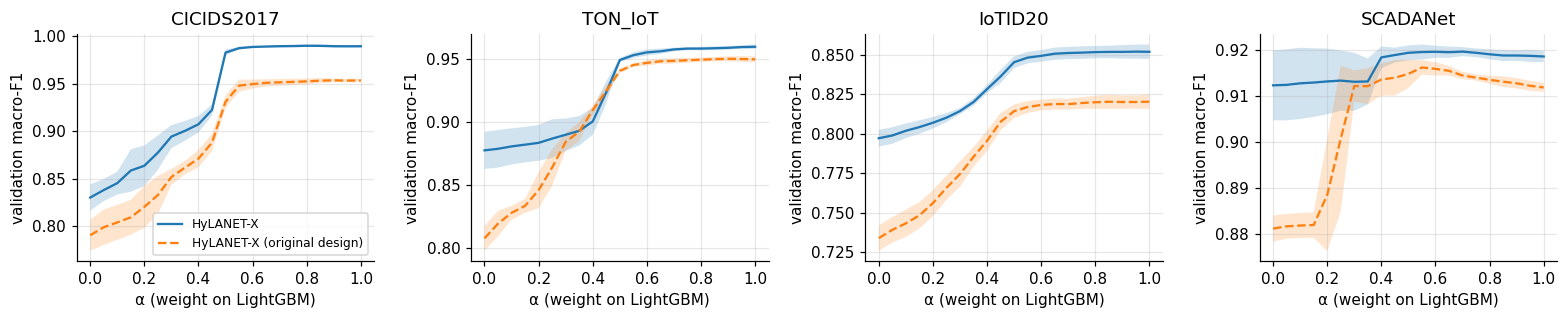

[table] complementarity_test


,dataset,protocol,pair (A | B),acc_a,acc_b,disagreement,double_fault,only_a_correct,only_b_correct,oracle_acc,q_statistic
0,CICIDS2017,random,LGBM | FTA,0.9986,0.9584,0.0410,0.0010,0.0406,0.0004,0.9990,0.9643
1,CICIDS2017,random,LGBM-pca | CNN-BiLSTM-Tr,0.9925,0.9391,0.0577,0.0053,0.0555,0.0022,0.9947,0.9507
2,CICIDS2017,random,RF | LGBM,0.9983,0.9986,0.0011,0.0010,0.0004,0.0007,0.9990,0.9994
3,IoTID20,random,LGBM | FTA,0.9277,0.8687,0.0804,0.0616,0.0697,0.0107,0.9384,0.9721
4,IoTID20,random,LGBM-pca | CNN-BiLSTM-Tr,0.9056,0.8013,0.1294,0.0819,0.1168,0.0125,0.9181,0.9557
5,IoTID20,random,RF | LGBM,0.9348,0.9277,0.0319,0.0528,0.0195,0.0124,0.9472,0.9901
6,IoTID20,temporal,LGBM | FTA,0.4029,0.3661,0.0890,0.5710,0.0629,0.0261,0.4290,0.9822
7,IoTID20,temporal,LGBM-pca | CNN-BiLSTM-Tr,0.3537,0.3126,0.0729,0.6304,0.0570,0.0159,0.3696,0.9892
8,IoTID20,temporal,RF | LGBM,0.4244,0.4029,0.0586,0.5570,0.0401,0.0186,0.4430,0.9932
9,SCADANet,random,LGBM | FTA,0.9747,0.9652,0.0175,0.0213,0.0135,0.0040,0.9787,0.9947



✓ Cell ran successfully (0.8 s)


In [38]:
# Fusion weight alpha: selected values and validation curves
rows = []
for r in RECS:
    for f, a in r["alpha"].items():
        rows.append({"dataset": r["dataset"], "protocol": r["protocol"], "seed": r["seed"],
                     "fusion": f, "alpha": a})
A = pd.DataFrame(rows)
if len(A):
    summary = (A.groupby(["dataset", "protocol", "fusion"])["alpha"]
               .agg(selected=lambda s: ", ".join(f"{v:.2f}" for v in s), median="median",
                    runs_at_1=lambda s: int((s >= 0.999).sum()), runs="count").reset_index())
    save_table(summary, "alpha_selected")

    dss = [d for d in DS_ORDER if any(r["dataset"] == d for r in RECS)]
    fig, axes = plt.subplots(1, len(dss), figsize=(3.6 * len(dss), 3.0), squeeze=False)
    for ax, ds in zip(axes[0], dss):
        for fname, style in [("HyLANET-X", "-"), ("HyLANET-X (original design)", "--")]:
            curves = np.array([r["alpha_curve"][fname] for r in RECS
                               if r["dataset"] == ds and r["protocol"] == "random"])
            if len(curves) == 0:
                continue
            mu, sd = curves.mean(0), curves.std(0)
            ax.plot(ALPHAS, mu, style, label=fname)
            ax.fill_between(ALPHAS, mu - sd, mu + sd, alpha=0.2)
        ax.set_title(ds)
        ax.set_xlabel("α (weight on LightGBM)")
        ax.set_ylabel("validation macro-F1")
    axes[0][0].legend(fontsize=8)
    fig.tight_layout()
    save_fig(fig, "alpha_validation_curves")

# How often do the two branches make different mistakes?
rows = []
for r in RECS:
    for pair, v in r["complementarity"].items():
        rows.append({"dataset": r["dataset"], "protocol": r["protocol"], "seed": r["seed"],
                     "pair (A | B)": pair, **v["test"]})
C = pd.DataFrame(rows)
if len(C):
    cols = ["acc_a", "acc_b", "disagreement", "double_fault", "only_a_correct", "only_b_correct",
            "oracle_acc", "q_statistic"]
    comp = C.groupby(["dataset", "protocol", "pair (A | B)"])[cols].mean().reset_index()
    comp[cols] = comp[cols].round(4)
    save_table(comp, "complementarity_test")

In [39]:
# Random vs time-ordered split
sub = RES[RES.model.isin(MAIN_MODELS)]
if set(sub.protocol) >= {"random", "temporal"}:
    g = sub.groupby(["dataset", "model", "protocol"])["f1_macro"].mean().unstack()
    g = g.dropna()
    g["drop (points)"] = 100 * (g["random"] - g["temporal"])
    g[["random", "temporal"]] = 100 * g[["random", "temporal"]]
    save_table(g.round(2).reset_index(), "random_vs_temporal_macro_f1")

# Raw features vs PCA components (same seeds for both)
pairs = [("RF", "RF", "RF-pca"), ("LightGBM", "LGBM", "LGBM-pca"), ("FTA", "FTA", "FTA-pca"),
         ("CNN-BiLSTM-Tr", "CNN-BiLSTM-Tr-raw", "CNN-BiLSTM-Tr")]
sub = RES[(RES.protocol == "random") & RES.seed.isin(EXTRA_SEEDS)]
rows = []
for ds in DS_ORDER:
    for label, raw_m, pca_m in pairs:
        a, b = sub[(sub.dataset == ds) & (sub.model == raw_m)], sub[(sub.dataset == ds) & (sub.model == pca_m)]
        if len(a) and len(b):
            rows.append({"dataset": ds, "model": label, "raw features": pm(a["f1_macro"]),
                         "PCA components": pm(b["f1_macro"]),
                         "raw - PCA (points)": round(100 * (a["f1_macro"].mean() - b["f1_macro"].mean()), 2)})
if rows:
    save_table(pd.DataFrame(rows), "raw_vs_pca_macro_f1")

# Does the order of the PCA components matter to the sequence model?
rows = []
for ds in DS_ORDER:
    vals = {m: sub[(sub.dataset == ds) & (sub.model == m)]["f1_macro"]
            for m in ["CNN-BiLSTM-Tr", "CNN-BiLSTM-Tr-shuffled", "CNN-BiLSTM-Tr-reversed"]}
    if all(len(v) for v in vals.values()):
        rows.append({"dataset": ds, "original order": pm(vals["CNN-BiLSTM-Tr"]),
                     "random order": pm(vals["CNN-BiLSTM-Tr-shuffled"]),
                     "reversed order": pm(vals["CNN-BiLSTM-Tr-reversed"])})
if rows:
    save_table(pd.DataFrame(rows), "pca_order_permutation")

[table] random_vs_temporal_macro_f1


protocol,dataset,model,random,temporal,drop (points)
0,IoTID20,CNN-BiLSTM-Tr,73.46,40.03,33.43
1,IoTID20,FTA,79.77,46.20,33.57
2,IoTID20,HyLANET-X,85.25,46.38,38.87
3,IoTID20,HyLANET-X (original design),82.11,42.98,39.12
4,IoTID20,HyLANET-X (stacked),83.91,51.81,32.11
5,IoTID20,LGBM,85.28,47.94,37.34
6,IoTID20,MLP,79.62,45.88,33.74
7,IoTID20,RF,85.29,49.34,35.95
8,IoTID20,RF+LGBM,85.51,49.34,36.17
9,IoTID20,SVM,71.42,45.94,25.47


[table] raw_vs_pca_macro_f1


,dataset,model,raw features,PCA components,raw - PCA (points)
0,CICIDS2017,RF,98.88 ± 0.08,97.46 ± 0.33,1.42
1,CICIDS2017,LightGBM,98.83 ± 0.30,95.51 ± 0.36,3.32
2,CICIDS2017,FTA,83.49 ± 1.15,80.87 ± 1.15,2.61
3,CICIDS2017,CNN-BiLSTM-Tr,79.26 ± 4.27,80.08 ± 2.01,-0.82
4,TON_IoT,RF,95.72 ± 0.08,95.25 ± 0.12,0.48
5,TON_IoT,LightGBM,95.90 ± 0.14,94.74 ± 0.15,1.17
6,TON_IoT,FTA,86.95 ± 1.79,83.54 ± 2.96,3.40
7,TON_IoT,CNN-BiLSTM-Tr,81.97 ± 2.69,80.77 ± 1.27,1.20
8,IoTID20,RF,85.24 ± 0.45,82.91 ± 0.29,2.33
9,IoTID20,LightGBM,85.19 ± 0.29,82.12 ± 0.18,3.06


[table] pca_order_permutation


,dataset,original order,random order,reversed order
0,CICIDS2017,80.08 ± 2.01,80.62 ± 2.86,79.45 ± 2.91
1,TON_IoT,80.77 ± 1.27,80.00 ± 3.53,79.43 ± 2.43
2,IoTID20,73.88 ± 0.96,74.04 ± 0.86,74.68 ± 0.83
3,SCADANet,88.30 ± 0.02,89.43 ± 0.27,88.17 ± 0.24



✓ Cell ran successfully (0.0 s)


In [40]:
# Per-class results (random protocol, mean over seeds)
PC_MODELS = ["RF", "LGBM", "MLP", "SVM", "CNN-BiLSTM-Tr", "FTA", "HyLANET-X"]
for ds in DS_ORDER:
    recs = [r for r in RECS if r["dataset"] == ds and r["protocol"] == "random"]
    if not recs:
        continue
    classes = recs[0]["classes"]
    rows = []
    for c in classes:
        row = {"class": c, "test support": recs[0]["per_class"]["RF"][c]["support"]}
        for m in PC_MODELS:
            for k, short in (("precision", "P"), ("recall", "R"), ("f1", "F1")):
                row[f"{m} {short}"] = round(float(np.mean([r["per_class"][m][c][k] for r in recs])), 4)
        rows.append(row)
    save_table(pd.DataFrame(rows), f"per_class_{ds}")

# Confusion matrices (seed 42, random protocol) for every model
CM_MODELS = ["RF", "LGBM", "SVM", "MLP", "CNN-BiLSTM-Tr", "FTA", "HyLANET-X"]
for r in tqdm([r for r in RECS if r["seed"] == TUNE_SEED and r["protocol"] == "random"],
              desc="confusion matrices"):
    z = np.load(os.path.join(OUT_DIR, "preds", f"{r['dataset']}__random__{TUNE_SEED}.npz"))
    y, classes = z["y"], r["classes"]
    K = len(classes)
    for m in CM_MODELS:
        cm = confusion_matrix(y, z[r["pred_keys"][m]], labels=np.arange(K))
        pd.DataFrame(cm, index=classes, columns=classes).to_csv(
            os.path.join(OUT_DIR, "figures", "confusion", f"cm_{r['dataset']}_{safe_key(m)}.csv"))
        cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
        size = max(3.5, 0.45 * K + 1.5)
        fig, ax = plt.subplots(figsize=(size, size))
        ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
        ax.grid(False)
        for i in range(K):
            for j in range(K):
                if cm[i, j]:
                    ax.text(j, i, f"{cmn[i, j]:.2f}\n({cm[i, j]})", ha="center", va="center",
                            fontsize=6 if K > 8 else 7, color="white" if cmn[i, j] > 0.5 else "black")
        ax.set_xticks(range(K))
        ax.set_xticklabels(classes, rotation=45, ha="right", fontsize=7)
        ax.set_yticks(range(K))
        ax.set_yticklabels(classes, fontsize=7)
        ax.set_xlabel("Predicted")
        ax.set_ylabel("True")
        ax.set_title(f"{r['dataset']}: {m}", fontsize=9)
        fig.tight_layout()
        if SHOW_CONFUSION_FIGURES:
            save_fig(fig, f"cm_{r['dataset']}_{safe_key(m)}", sub="figures/confusion")
        else:
            for ext in ("pdf", "png"):
                fig.savefig(os.path.join(OUT_DIR, "figures/confusion",
                                         f"cm_{r['dataset']}_{safe_key(m)}.{ext}"), bbox_inches="tight")
            plt.close(fig)

[table] per_class_CICIDS2017


,class,test support,RF P,RF R,RF F1,LGBM P,LGBM R,LGBM F1,MLP P,MLP R,...,SVM F1,CNN-BiLSTM-Tr P,CNN-BiLSTM-Tr R,CNN-BiLSTM-Tr F1,FTA P,FTA R,FTA F1,HyLANET-X P,HyLANET-X R,HyLANET-X F1
0,BENIGN,25000,0.9983,0.9984,0.9983,0.9992,0.9983,0.9988,0.9728,0.9436,...,0.9602,0.9622,0.9123,0.9364,0.9863,0.9327,0.9585,0.9993,0.9983,0.9988
1,Bot,353,0.9480,0.9802,0.9638,0.9347,0.9898,0.9615,0.4775,0.9677,...,0.8033,0.4424,0.9581,0.5962,0.3907,0.9926,0.5602,0.9334,0.9926,0.9621
2,BruteForce,2288,0.9997,0.9974,0.9986,0.9997,0.9986,0.9992,0.8933,0.9774,...,0.9696,0.8987,0.9675,0.9317,0.9489,0.9688,0.9583,0.9997,0.9986,0.9992
3,DoS,25000,0.9991,0.9991,0.9991,0.9993,0.9994,0.9993,0.9895,0.9723,...,0.9694,0.9772,0.9621,0.9694,0.9771,0.9827,0.9797,0.9993,0.9994,0.9993
4,PortScan,462,0.9861,0.9818,0.9839,0.9777,0.9866,0.9821,0.8429,0.9571,...,0.8147,0.6218,0.9463,0.7462,0.6897,0.9623,0.7917,0.9782,0.9870,0.9826
5,WebAttack,536,0.9962,0.9825,0.9893,0.9951,0.9918,0.9935,0.5150,0.9604,...,0.8998,0.4193,0.9787,0.5794,0.6300,0.9575,0.7379,0.9951,0.9925,0.9938


[table] per_class_TON_IoT


,class,test support,RF P,RF R,RF F1,LGBM P,LGBM R,LGBM F1,MLP P,MLP R,...,SVM F1,CNN-BiLSTM-Tr P,CNN-BiLSTM-Tr R,CNN-BiLSTM-Tr F1,FTA P,FTA R,FTA F1,HyLANET-X P,HyLANET-X R,HyLANET-X F1
0,backdoor,606,0.9961,0.9970,0.9965,0.9925,0.9970,0.9947,0.7809,0.5624,...,0.0085,0.8269,0.5637,0.6703,0.6864,0.8241,0.7271,0.9928,0.9970,0.9949
1,ddos,3116,0.9859,0.9813,0.9836,0.9870,0.9820,0.9845,0.9686,0.9406,...,0.7487,0.9477,0.8899,0.9179,0.9744,0.9458,0.9599,0.9873,0.9820,0.9846
2,dos,3614,0.9919,0.9696,0.9806,0.9934,0.9704,0.9818,0.8335,0.9340,...,0.8196,0.8204,0.9112,0.8634,0.9131,0.8852,0.8969,0.9939,0.9703,0.9819
3,injection,4932,0.9865,0.9720,0.9792,0.9915,0.9705,0.9809,0.9605,0.9224,...,0.6765,0.8511,0.6623,0.7442,0.9727,0.9141,0.9412,0.9916,0.9705,0.9810
4,mitm,259,0.6268,0.9042,0.7400,0.6220,0.9205,0.7422,0.4089,0.9290,...,0.4114,0.3381,0.9166,0.4928,0.3996,0.9413,0.5603,0.6181,0.9236,0.7404
5,normal,6088,0.9952,0.9933,0.9942,0.9963,0.9936,0.9950,0.9954,0.9583,...,0.9536,0.9934,0.9509,0.9717,0.9959,0.9588,0.9770,0.9964,0.9937,0.9950
6,password,3838,0.9968,0.9859,0.9914,0.9964,0.9866,0.9915,0.9696,0.8977,...,0.7054,0.6982,0.8313,0.7585,0.9467,0.9428,0.9426,0.9965,0.9866,0.9915
7,ransomware,308,0.9840,0.9955,0.9897,0.9878,0.9968,0.9922,0.9101,0.9799,...,0.8290,0.8891,0.9779,0.9312,0.9057,0.9818,0.9421,0.9878,0.9968,0.9922
8,scanning,1398,0.9499,0.9754,0.9625,0.9520,0.9810,0.9663,0.9151,0.8439,...,0.3917,0.9050,0.8216,0.8612,0.9044,0.8861,0.8950,0.9525,0.9811,0.9665
9,xss,2163,0.9460,0.9743,0.9599,0.9453,0.9828,0.9637,0.8295,0.9379,...,0.6720,0.7917,0.8804,0.8337,0.8653,0.9439,0.9026,0.9452,0.9832,0.9638


[table] per_class_IoTID20


,class,test support,RF P,RF R,RF F1,LGBM P,LGBM R,LGBM F1,MLP P,MLP R,...,SVM F1,CNN-BiLSTM-Tr P,CNN-BiLSTM-Tr R,CNN-BiLSTM-Tr F1,FTA P,FTA R,FTA F1,HyLANET-X P,HyLANET-X R,HyLANET-X F1
0,DoS,5046,0.9992,0.9980,0.9986,0.9994,0.9982,0.9988,0.9987,0.9962,...,0.9970,0.9983,0.9930,0.9956,0.9983,0.9966,0.9974,0.9994,0.9981,0.9988
1,MITM ARP Spoofing,1644,0.4886,0.6281,0.5496,0.4386,0.7775,0.5607,0.2797,0.8895,...,0.3540,0.2125,0.9046,0.3442,0.2794,0.9084,0.4273,0.4332,0.7871,0.5586
2,Mirai,23647,0.9633,0.9442,0.9537,0.9817,0.9182,0.9489,0.9912,0.8251,...,0.8694,0.9931,0.7332,0.8435,0.9936,0.8204,0.8987,0.9826,0.9162,0.9482
3,Normal,6697,0.9947,0.9828,0.9887,0.9935,0.9855,0.9895,0.9821,0.9694,...,0.9009,0.9301,0.9180,0.9239,0.9751,0.9778,0.9764,0.9936,0.9855,0.9895
4,Scan,2443,0.7613,0.7874,0.7741,0.7219,0.8157,0.7659,0.6268,0.7481,...,0.4495,0.4883,0.6744,0.5657,0.6403,0.7456,0.6885,0.7240,0.8163,0.7674


[table] per_class_SCADANet


,class,test support,RF P,RF R,RF F1,LGBM P,LGBM R,LGBM F1,MLP P,MLP R,...,SVM F1,CNN-BiLSTM-Tr P,CNN-BiLSTM-Tr R,CNN-BiLSTM-Tr F1,FTA P,FTA R,FTA F1,HyLANET-X P,HyLANET-X R,HyLANET-X F1
0,apt_exfil,557,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,...,0.9713,0.9940,0.9996,0.9968,0.9996,0.9993,0.9995,1.0000,1.0000,1.0000
1,http_flood,3526,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.9981,1.0000,...,0.9971,0.9945,1.0000,0.9972,0.9948,1.0000,0.9974,1.0000,1.0000,1.0000
2,icmp_flood,4643,0.9991,1.0000,0.9996,0.9991,1.0000,0.9996,0.9986,1.0000,...,0.9991,0.9976,1.0000,0.9988,0.9979,1.0000,0.9989,0.9991,1.0000,0.9995
3,insider_threat,376,0.9863,0.9957,0.9910,0.9989,1.0000,0.9995,0.9871,0.9739,...,0.8109,0.9968,0.4745,0.6425,0.9917,0.9149,0.9426,0.9984,1.0000,0.9992
4,modbus_abuse,149,0.9855,0.9973,0.9913,0.9921,0.9973,0.9947,0.9973,0.9973,...,0.9466,0.9987,0.9973,0.9980,0.9920,0.9973,0.9947,0.9921,0.9973,0.9947
5,modbus_fdi,734,0.9978,0.9921,0.9949,1.0000,0.9981,0.9990,0.9877,0.9940,...,0.9283,0.7890,0.9995,0.8819,0.9633,0.9975,0.9787,1.0000,0.9986,0.9993
6,normal_traffic,16697,0.9985,0.9274,0.9616,0.9985,0.9304,0.9633,0.9979,0.8926,...,0.9273,0.9976,0.8870,0.9391,0.9981,0.8882,0.9400,0.9991,0.9266,0.9615
7,os_scan,122,0.0805,0.3623,0.1314,0.0715,0.4049,0.1214,0.0739,0.4590,...,0.1212,0.0713,0.4557,0.1233,0.0720,0.4623,0.1245,0.0727,0.4230,0.1240
8,port_scan,390,0.9620,0.9426,0.9521,0.9674,0.9426,0.9548,0.9897,0.9364,...,0.9479,0.9887,0.9369,0.9621,0.9935,0.9364,0.9641,0.9818,0.9405,0.9607
9,sql_injection,94,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,...,0.9423,0.9407,1.0000,0.9683,0.9979,1.0000,0.9989,1.0000,1.0000,1.0000


confusion matrices:   0%|          | 0/4 [00:00<?, ?it/s]


✓ Cell ran successfully (11.7 s)


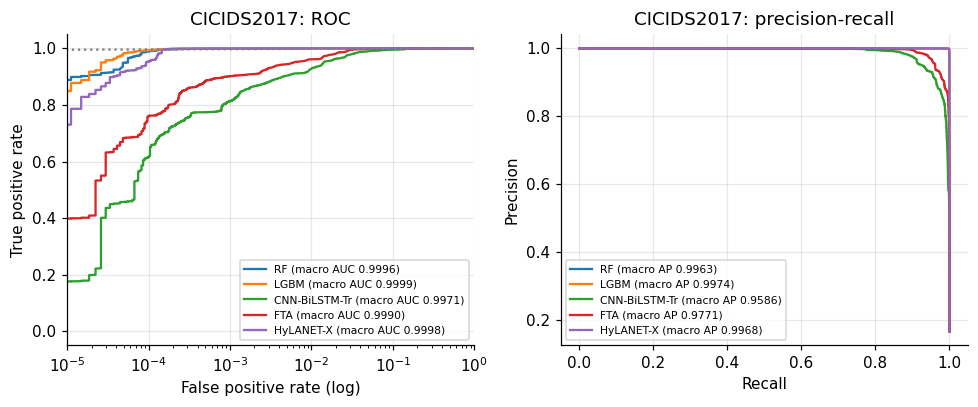

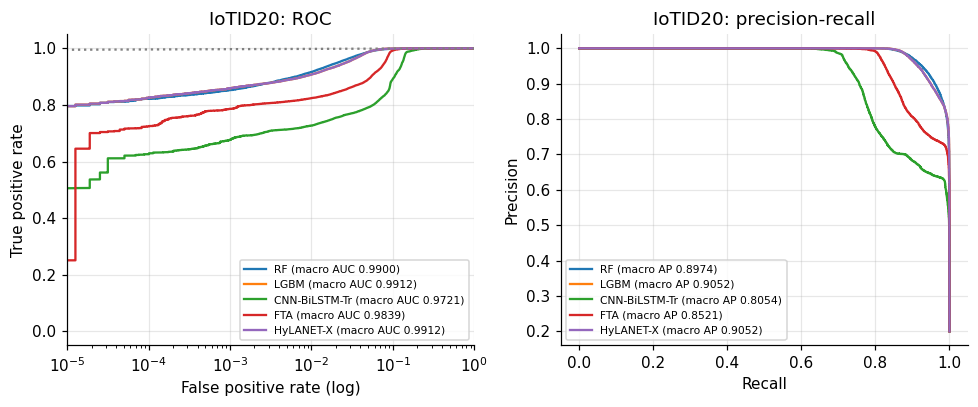

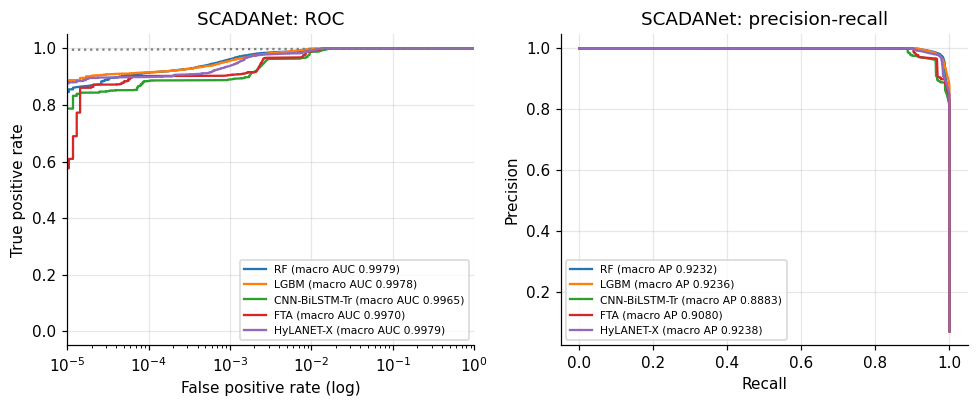

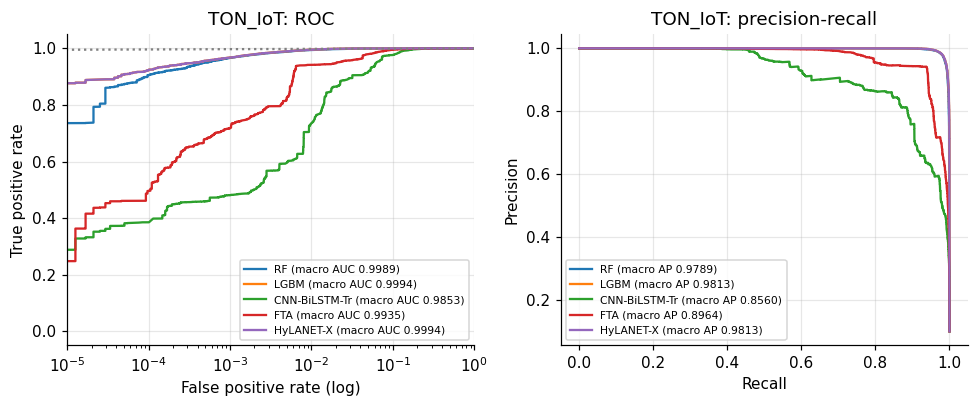

[table] roc_pr_auc


,dataset,model,ROC-AUC (macro),PR-AUC (macro)
0,CICIDS2017,RF,99.97 ± 0.02,99.58 ± 0.13
1,CICIDS2017,LGBM,99.99 ± 0.01,99.65 ± 0.11
2,CICIDS2017,SVM,99.66 ± 0.06,91.87 ± 0.52
3,CICIDS2017,MLP,99.81 ± 0.13,95.56 ± 2.98
4,CICIDS2017,CNN-BiLSTM-Tr,99.67 ± 0.05,95.17 ± 1.14
5,CICIDS2017,FTA,99.83 ± 0.10,96.36 ± 1.63
6,CICIDS2017,HyLANET-X,99.99 ± 0.01,99.58 ± 0.10
7,CICIDS2017,HyLANET-X (stacked),99.98 ± 0.01,99.19 ± 0.30
8,CICIDS2017,HyLANET-X (original design),99.95 ± 0.02,98.49 ± 0.15
9,CICIDS2017,RF+LGBM,99.99 ± 0.00,99.64 ± 0.12



✓ Cell ran successfully (5.1 s)


In [41]:
# ROC and precision-recall curves (seed 42, random protocol, micro-averaged one-vs-rest)
CURVE_MODELS = ["RF", "LGBM", "CNN-BiLSTM-Tr", "FTA", "HyLANET-X"]
for r in RECS:
    if r["seed"] != TUNE_SEED or r["protocol"] != "random":
        continue
    f = os.path.join(OUT_DIR, "probs", f"{r['dataset']}__random__{TUNE_SEED}.npz")
    if not os.path.exists(f):
        continue
    z = np.load(f)
    y, K = z["y"], len(r["classes"])
    Y = np.eye(K)[y]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.8))
    for m in CURVE_MODELS:
        Pm = z[r["pred_keys"][m]]
        fpr, tpr, _ = roc_curve(Y.ravel(), Pm.ravel())
        prec, rec, _ = precision_recall_curve(Y.ravel(), Pm.ravel())
        met = r["metrics"][m]
        a1.plot(fpr, tpr, label=f"{m} (macro AUC {met['roc_auc_macro']:.4f})")
        a2.plot(rec, prec, label=f"{m} (macro AP {met['pr_auc_macro']:.4f})")
    a1.plot([0, 1], [0, 1], ":", color="grey")
    a1.set_xscale("log")
    a1.set_xlim(1e-5, 1)
    a1.set_xlabel("False positive rate (log)")
    a1.set_ylabel("True positive rate")
    a1.set_title(f"{r['dataset']}: ROC")
    a2.set_xlabel("Recall")
    a2.set_ylabel("Precision")
    a2.set_title(f"{r['dataset']}: precision-recall")
    a1.legend(fontsize=7, loc="lower right")
    a2.legend(fontsize=7, loc="lower left")
    fig.tight_layout()
    save_fig(fig, f"roc_pr_{r['dataset']}")

auc_rows = []
for ds in DS_ORDER:
    s = RES[(RES.protocol == "random") & (RES.dataset == ds) & RES.model.isin(MAIN_MODELS)]
    for m in MAIN_MODELS:
        g = s[s.model == m]
        if len(g):
            auc_rows.append({"dataset": ds, "model": m, "ROC-AUC (macro)": pm(g["roc_auc_macro"]),
                             "PR-AUC (macro)": pm(g["pr_auc_macro"])})
if auc_rows:
    save_table(pd.DataFrame(auc_rows), "roc_pr_auc")

[table] efficiency


,dataset,model,parameters,trees,nodes,leaves,size_MB,train_time_s,latency_ms_median,latency_ms_p95,throughput_rows_per_s,cpu_threads
0,CICIDS2017,RF,NaN,300.0,273654.0,NaN,29.354,5.850,5.884,6.081,97261.466,1
1,CICIDS2017,LGBM,NaN,876.0,NaN,15609.0,1.769,75.990,0.307,0.321,33243.233,1
2,CICIDS2017,SVM,408.0,NaN,NaN,NaN,0.004,310.035,0.036,0.042,3131904.039,1
3,CICIDS2017,MLP,84742.0,NaN,NaN,NaN,0.326,6.535,0.034,0.036,81285.816,56
4,CICIDS2017,FTA,21670.0,NaN,NaN,NaN,0.092,62.711,117.999,120.016,16236.508,56
5,CICIDS2017,LGBM-pca,NaN,1488.0,NaN,26769.0,2.986,10.123,0.320,0.332,15159.802,1
6,CICIDS2017,CNN-BiLSTM-Tr,191558.0,NaN,NaN,NaN,0.737,17.037,1.491,1.518,18140.393,56
7,IoTID20,RF,NaN,300.0,2012842.0,NaN,199.761,3.545,5.838,6.008,47793.984,1
8,IoTID20,LGBM,NaN,935.0,NaN,182008.0,19.010,729.178,0.362,0.373,12817.508,1
9,IoTID20,SVM,345.0,NaN,NaN,NaN,0.003,1501.919,0.036,0.042,5535813.177,1


Hardware: x86_64 | 256 CPU threads | GPU: NVIDIA L4, NVIDIA L4


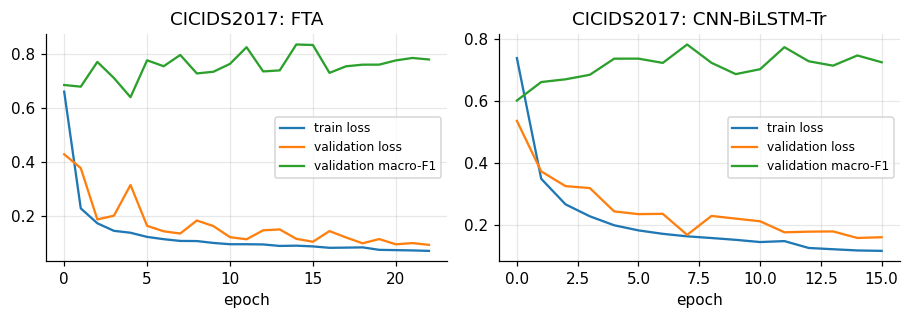

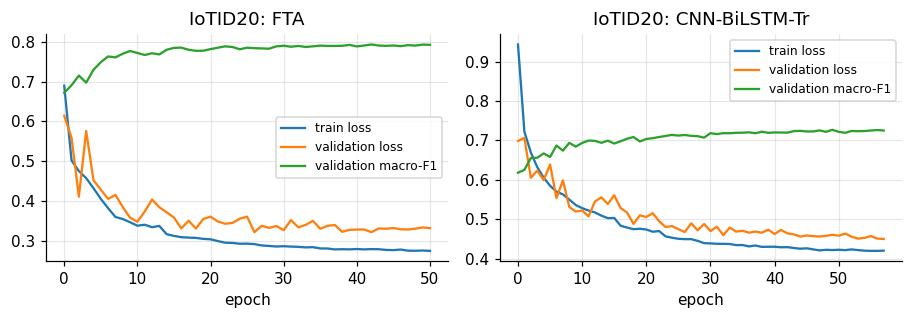

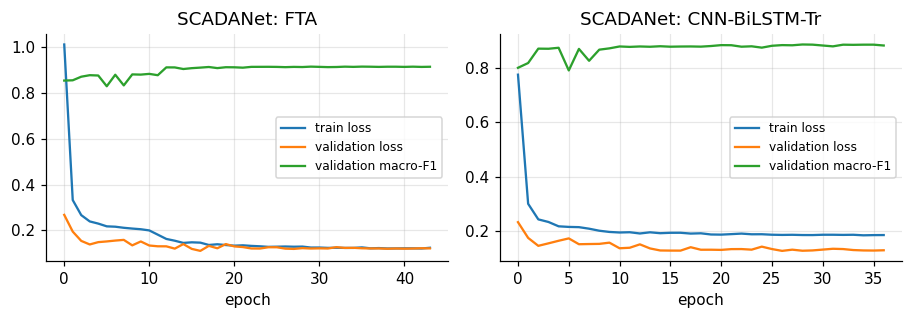

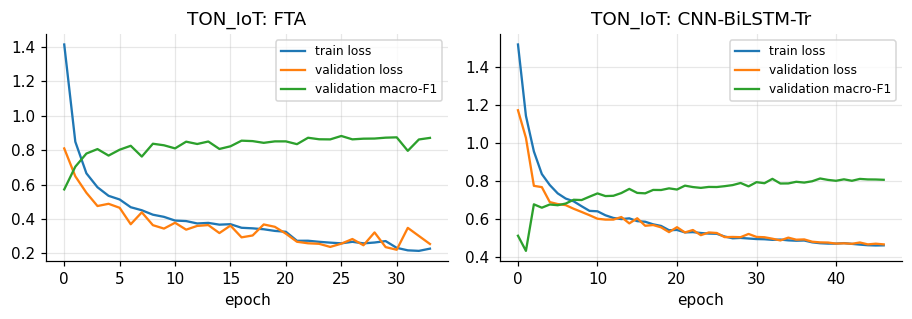

[table] split_summary


,dataset,protocol,classes,train,validation,test,features used,PCA components (95%),text columns kept,columns dropped,test rows matching a train row
0,CICIDS2017,random,6,128733,32183,53639,67,24,0,0,3991
1,IoTID20,random,5,94743,23685,39477,68,23,0,0,601
2,IoTID20,temporal,5,93958,22900,39477,68,22,0,0,23
3,SCADANet,random,14,140423,35106,58510,40,22,23,7,27648
4,SCADANet,temporal,14,139264,33940,58511,40,23,23,7,20807
5,TON_IoT,random,10,63169,15792,26322,39,21,24,0,19879



✓ Cell ran successfully (2.2 s)


In [42]:
# Computational cost (seed 42, random protocol). Latency is one flow at a time on the CPU.
rows = []
for r in RECS:
    for m, e in r.get("efficiency", {}).items():
        rows.append({"dataset": r["dataset"], "model": m, **e})
EFF = pd.DataFrame(rows)
if len(EFF):
    EFF["size_MB"] = EFF["size_bytes"] / 2 ** 20
    extra = []
    for ds in EFF.dataset.unique():
        for fname, (a, b) in FUSIONS.items():
            ea, eb = EFF[(EFF.dataset == ds) & (EFF.model == a)], EFF[(EFF.dataset == ds) & (EFF.model == b)]
            if len(ea) and len(eb):
                ea, eb = ea.iloc[0], eb.iloc[0]
                # A fusion runs both models, so size, training time and latency add up.
                extra.append({"dataset": ds, "model": fname, "size_MB": ea.size_MB + eb.size_MB,
                              "train_time_s": ea.train_time_s + eb.train_time_s,
                              "latency_ms_median": ea.latency_ms_median + eb.latency_ms_median,
                              "latency_ms_p95": ea.latency_ms_p95 + eb.latency_ms_p95,
                              "throughput_rows_per_s": 1.0 / (1.0 / ea.throughput_rows_per_s
                                                              + 1.0 / eb.throughput_rows_per_s)})
    EFF = pd.concat([EFF, pd.DataFrame(extra)], ignore_index=True)
    cols = ["dataset", "model", "parameters", "trees", "nodes", "leaves", "size_MB", "train_time_s",
            "latency_ms_median", "latency_ms_p95", "throughput_rows_per_s", "cpu_threads"]
    save_table(EFF[[c for c in cols if c in EFF.columns]].round(3), "efficiency")
    print("Hardware:", ENV["processor"] or ENV["platform"], "|", ENV["cpu_count"], "CPU threads |",
          "GPU:", ", ".join(ENV["gpus"]) or "none")

# Training curves of the deep models (seed 42, random protocol)
for r in RECS:
    if r["seed"] != TUNE_SEED or r["protocol"] != "random" or not r["history"]:
        continue
    models = [m for m in ["FTA", "CNN-BiLSTM-Tr"] if m in r["history"]]
    fig, axes = plt.subplots(1, len(models), figsize=(4.2 * len(models), 3.0), squeeze=False)
    for ax, m in zip(axes[0], models):
        h = r["history"][m]
        ax.plot(h["loss"], label="train loss")
        ax.plot(h["val_loss"], label="validation loss")
        if "val_macro_f1" in h:
            ax.plot(h["val_macro_f1"], label="validation macro-F1")
        ax.set_title(f"{r['dataset']}: {m}")
        ax.set_xlabel("epoch")
        ax.legend(fontsize=8)
    fig.tight_layout()
    save_fig(fig, f"training_curves_{r['dataset']}")

# Dataset table for the paper (rows after cleaning, split sizes, PCA dimension, near duplicates)
rows = []
for r in RECS:
    if r["seed"] == TUNE_SEED:
        rows.append({"dataset": r["dataset"], "protocol": r["protocol"], "classes": len(r["classes"]),
                     "train": r["n_train"], "validation": r["n_val"], "test": r["n_test"],
                     "features used": r["n_features"], "PCA components (95%)": r["n_pca"],
                     "text columns kept": len(r["categorical_features"]),
                     "columns dropped": len(r["dropped_columns"]),
                     "test rows matching a train row": r["test_rows_matching_a_train_row"]})
if rows:
    save_table(pd.DataFrame(rows), "split_summary")

## 7. Cross-dataset transfer (CICIDS2017 and IoTID20)

Both datasets were produced with CICFlowMeter, so many flow features can be matched by name. The task is binary (normal vs attack). Models are trained on one dataset (train split, with α chosen on its validation split) and tested on all rows of the other. Features are matched after normalising the naming differences between the two CICFlowMeter versions. The matched pairs are saved, so you can check them. TON_IoT (Zeek features) and SCADANet (packet fields) use different feature spaces, so a direct transfer is not defined for them.

transfer CICIDS2017 -> IoTID20:   0%|          | 0/3 [00:00<?, ?it/s]

FTA:   0%|          | 0/60 [00:00<?, ?it/s]

FTA:   0%|          | 0/60 [00:00<?, ?it/s]

FTA:   0%|          | 0/60 [00:00<?, ?it/s]

transfer IoTID20 -> CICIDS2017:   0%|          | 0/3 [00:00<?, ?it/s]

...

FTA:   0%|          | 0/60 [00:00<?, ?it/s]

matched features (77): [('Protocol', 'Protocol'), ('Flow Duration', 'Flow_Duration'), ('Total Fwd Packets', 'Tot_Fwd_Pkts'), ('Total Backward Packets', 'Tot_Bwd_Pkts'), ('Fwd Packets Length Total', 'TotLen_Fwd_Pkts'), ('Bwd Packets Length Total', 'TotLen_Bwd_Pkts'), ('Fwd Packet Length Max', 'Fwd_Pkt_Len_Max'), ('Fwd Packet Length Min', 'Fwd_Pkt_Len_Min'), ('Fwd Packet Length Mean', 'Fwd_Pkt_Len_Mean'), ('Fwd Packet Length Std', 'Fwd_Pkt_Len_Std'), ('Bwd Packet Length Max', 'Bwd_Pkt_Len_Max'), ('Bwd Packet Length Min', 'Bwd_Pkt_Len_Min'), ('Bwd Packet Length Mean', 'Bwd_Pkt_Len_Mean'), ('Bwd Packet Length Std', 'Bwd_Pkt_Len_Std'), ('Flow Bytes/s', 'Flow_Byts/s'), ('Flow Packets/s', 'Flow_Pkts/s'), ('Flow IAT Mean', 'Flow_IAT_Mean'), ('Flow IAT Std', 'Flow_IAT_Std'), ('Flow IAT Max', 'Flow_IAT_Max'), ('Flow IAT Min', 'Flow_IAT_Min'), ('Fwd IAT Total', 'Fwd_IAT_Tot'), ('Fwd IAT Mean', 'Fwd_IAT_Mean'), ('Fwd IAT Std', 'Fwd_IAT_Std'), ('Fwd IAT Max', 'Fwd_IAT_Max'), ('Fwd IAT Min', 'Fwd_IA

,train on,test on,model,in-domain macro-F1,transfer macro-F1,transfer balanced acc.,transfer ROC-AUC
0,CICIDS2017,IoTID20,RF,99.83 ± 0.00,16.03 ± 0.43,48.66 ± 1.07,35.25 ± 2.64
1,CICIDS2017,IoTID20,LGBM,99.88 ± 0.03,14.52 ± 0.01,50.01 ± 0.00,45.09 ± 9.84
2,CICIDS2017,IoTID20,FTA,99.39 ± 0.02,28.94 ± 4.29,52.44 ± 3.78,39.42 ± 2.79
3,CICIDS2017,IoTID20,HyLANET-X,99.88 ± 0.02,14.59 ± 0.11,50.04 ± 0.05,38.81 ± 1.66
4,IoTID20,CICIDS2017,RF,96.89 ± 0.03,35.20 ± 0.31,50.18 ± 0.14,25.59 ± 6.60
5,IoTID20,CICIDS2017,LGBM,96.37 ± 0.04,35.09 ± 0.09,50.11 ± 0.02,24.57 ± 6.98
6,IoTID20,CICIDS2017,FTA,96.82 ± 0.39,38.25 ± 2.20,51.14 ± 1.00,67.36 ± 1.18
7,IoTID20,CICIDS2017,HyLANET-X,97.35 ± 0.21,36.30 ± 1.02,50.45 ± 0.34,58.02 ± 6.17


[table] transfer_feature_shift_ks


,feature,KS statistic
68,Fwd Seg Size Min,0.9995
37,Bwd Packets/s,0.8361
1,Flow Duration,0.8049
18,Flow IAT Max,0.7983
65,Init Fwd Win Bytes,0.7767
...,...,...
59,Bwd Avg Packets/Bulk,0.0000
56,Fwd Avg Packets/Bulk,0.0000
55,Fwd Avg Bytes/Bulk,0.0000
58,Bwd Avg Bytes/Bulk,0.0000


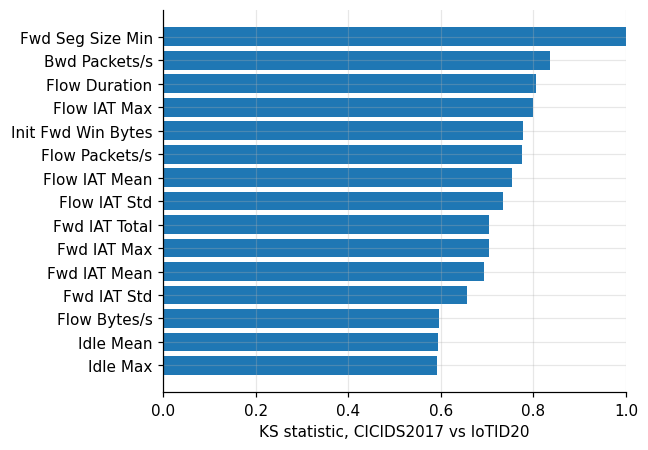


✓ Cell ran successfully (27.6 min)


In [43]:
CANON_TOKENS = {"total": "tot", "packets": "pkts", "packet": "pkts", "pkt": "pkts", "length": "len",
                "bytes": "byts", "byte": "byts", "count": "cnt", "average": "avg", "segment": "seg",
                "forward": "fwd", "backward": "bwd", "variance": "var", "bulk": "blk", "b": "blk",
                "destination": "dst", "source": "src", "flags": "flag", "of": ""}


def canon(name):
    s = re.sub(r"([a-z])([A-Z])", r"\1 \2", str(name))
    toks = [CANON_TOKENS.get(t, t) for t in re.split(r"[^A-Za-z0-9]+", s.lower()) if t]
    return " ".join(sorted(t for t in toks if t))


def matched_columns(src_cols, tgt_cols):
    tmap = {}
    for c in tgt_cols:
        tmap.setdefault(canon(c), c)
    pairs, seen = [], set()
    for c in src_cols:
        k = canon(c)
        if k in tmap and k not in seen:
            pairs.append((c, tmap[k]))
            seen.add(k)
    return pairs


def run_transfer(src, tgt, seed):
    path = os.path.join(OUT_DIR, "transfer", f"{src}__{tgt}__{seed}.json")
    if os.path.exists(path):
        return load_json(path)
    S, T = DATA[src], DATA[tgt]
    num = lambda X: [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
    pairs = matched_columns(num(S["X"]), num(T["X"]))
    cs, ct = [a for a, _ in pairs], [b for _, b in pairs]
    Xs = S["X"][cs]
    Xt = T["X"][ct].copy()
    Xt.columns = cs
    tr, va, te = get_split(src, "random", seed)
    ys, yt = S["y_bin"], T["y_bin"]
    prep = Prep().fit(Xs.iloc[tr])
    Rtr, Rva, Rte, Rtg = (prep.transform(X)[0] for X in (Xs.iloc[tr], Xs.iloc[va], Xs.iloc[te], Xt))
    out = {"source": src, "target": tgt, "seed": seed, "matched_features": pairs,
           "n_target": len(yt), "in_domain": {}, "transfer": {}}
    Pva, Pte, Ptg = {}, {}, {}
    for label, kind in [("RF", "rf"), ("LGBM", "lgbm"), ("FTA", "fta")]:
        r = fit_predict(kind, PARAMS[src][kind], Rtr, ys[tr], Rva, ys[va], Rte, 2, seed, desc=label)
        Pva[label], Pte[label], Ptg[label] = r["Pva"], r["Pte"], r["proba"](Rtg)
        del r
        free_memory()
    alpha, _ = select_alpha(Pva["LGBM"], Pva["FTA"], ys[va])
    Pte["HyLANET-X"] = alpha * Pte["LGBM"] + (1 - alpha) * Pte["FTA"]
    Ptg["HyLANET-X"] = alpha * Ptg["LGBM"] + (1 - alpha) * Ptg["FTA"]
    out["alpha"] = alpha
    for m in Pte:
        out["in_domain"][m] = compute_metrics(ys[te], Pte[m], 2)
        out["transfer"][m] = compute_metrics(yt, Ptg[m], 2)
    save_json(out, path)
    return out


TRANSFER_PAIRS = [("CICIDS2017", "IoTID20"), ("IoTID20", "CICIDS2017")]
if RUN["transfer"]:
    TR = []
    for src, tgt in TRANSFER_PAIRS:
        if src in DATA and tgt in DATA:
            for seed in tqdm(EXTRA_SEEDS, desc=f"transfer {src} -> {tgt}"):
                TR.append(run_transfer(src, tgt, seed))
    if TR:
        print(f"matched features ({len(TR[0]['matched_features'])}):", TR[0]["matched_features"])
        rows = []
        for (src, tgt) in TRANSFER_PAIRS:
            rs = [t for t in TR if t["source"] == src and t["target"] == tgt]
            for m in ["RF", "LGBM", "FTA", "HyLANET-X"]:
                if rs:
                    rows.append({"train on": src, "test on": tgt, "model": m,
                                 "in-domain macro-F1": pm([t["in_domain"][m]["f1_macro"] for t in rs]),
                                 "transfer macro-F1": pm([t["transfer"][m]["f1_macro"] for t in rs]),
                                 "transfer balanced acc.": pm([t["transfer"][m]["bal_acc"] for t in rs]),
                                 "transfer ROC-AUC": pm([t["transfer"][m]["roc_auc_macro"] for t in rs])})
        save_table(pd.DataFrame(rows), "transfer_results")
        pd.DataFrame(TR[0]["matched_features"], columns=["CICIDS2017 / source", "matched column"]).to_csv(
            os.path.join(OUT_DIR, "tables", "transfer_matched_features.csv"), index=False)

        # Distribution shift per matched feature (two-sample Kolmogorov-Smirnov statistic)
        src, tgt = TRANSFER_PAIRS[0]
        S, T = DATA[src], DATA[tgt]
        rng = np.random.RandomState(DATA_SEED)
        rows = []
        for a, b in TR[0]["matched_features"]:
            xa = pd.to_numeric(S["X"][a], errors="coerce").to_numpy(dtype=float)
            xb = pd.to_numeric(T["X"][b], errors="coerce").to_numpy(dtype=float)
            xa, xb = xa[np.isfinite(xa)], xb[np.isfinite(xb)]
            if len(xa) > 50000:
                xa = rng.choice(xa, 50000, replace=False)
            if len(xb) > 50000:
                xb = rng.choice(xb, 50000, replace=False)
            if len(xa) and len(xb):
                k = stats.ks_2samp(xa, xb)
                rows.append({"feature": a, "KS statistic": round(k.statistic, 4)})
        KS = pd.DataFrame(rows).sort_values("KS statistic", ascending=False)
        save_table(KS, "transfer_feature_shift_ks")
        top = KS.head(15).iloc[::-1]
        fig, ax = plt.subplots(figsize=(6, 4.2))
        ax.barh(top["feature"], top["KS statistic"])
        ax.set_xlabel(f"KS statistic, {src} vs {tgt}")
        ax.set_xlim(0, 1)
        fig.tight_layout()
        save_fig(fig, "transfer_feature_shift")

## 8. Where each output is used

| Output (in `OUT_DIR/tables` or `figures`) | Reviewer comment |
|---|---|
| `data_construction`, `class_distribution`, `dataset_overview`, `split_summary` | R2.4, R5.4 |
| `identifier_shortcut_check` | R4.2 (why identifier fields are removed) |
| `main_random_*`, `main_temporal_*`, `macro_f1_all_datasets_*` | R2.1, R4.2, R4.5 |
| `significance_wilcoxon`, `difference_ci_per_dataset`, `mcnemar_seed42` | R2.6, R4.7 |
| `alpha_selected`, `alpha_validation_curves` | R2.2, R2.3, R4.4 |
| `complementarity_test` | R2.1, R4.5 |
| `random_vs_temporal_macro_f1` | R2.5 |
| `raw_vs_pca_macro_f1`, `pca_order_permutation` | R2.7, R2.8, R4.6 |
| `model_ranks`, `ranking_agreement_kendall` | R4.3 |
| `per_class_*`, `figures/confusion/*` | R4.2 |
| `roc_pr_*`, `roc_pr_auc` | R5.3 |
| `search_space`, `selected_hyperparameters`, `tuning/*` | R5.5 |
| `efficiency`, `environment.json` | R2.9, R5.6 |
| `transfer_results`, `transfer_feature_shift*` | R2.10 |

In [44]:
import shutil
archive = shutil.make_archive(OUT_DIR, "zip", OUT_DIR)
print("All outputs zipped to", archive)

All outputs zipped to /home/hylanet_outputs_v2.zip

✓ Cell ran successfully (4.7 s)


In [1]:
# One-cell clean timing. Runs only the setup cells of this notebook (imports, settings, cached data,
# model code), then retrains the seed-42 models with 16 CPU threads and times every model on 1 thread.
import os, glob, json

NEEDED = ["# Installs what is missing", "import os, gc, re, json", "USE_KAGGLEHUB = True",
          "def to_jsonable(o):", "def list_data_files(path):", "# CICIDS2017 (original CIC release)",
          "DATA, audit_frames, class_frames", "def random_split(y, seed):", "def class_weights(y, K):",
          "class FTA(nn.Module):", "def model_size_bytes(kind, model):"]

nb_path = os.environ.get("JPY_SESSION_NAME", "")
if not nb_path.endswith(".ipynb") or not os.path.exists(nb_path):
    cands = [f for f in glob.glob("*.ipynb") if "class FTA(nn.Module)" in open(f, encoding="utf-8").read()]
    nb_path = max(cands, key=os.path.getmtime)
print("setup cells taken from:", nb_path)
cells = ["".join(c["source"]) for c in json.load(open(nb_path, encoding="utf-8"))["cells"] if c["cell_type"] == "code"]
for key in NEEDED:
    src = next((s for s in cells if s.lstrip().startswith(key)), None)
    if src is None:
        raise RuntimeError(f"cell starting with {key!r} not found in {nb_path}")
    print("running setup:", key)
    exec(compile(src, key, "exec"), globals())

if len(DATA) < 4:
    raise RuntimeError(f"only {list(DATA)} loaded from the cache in {OUT_DIR}/data_cache; stop and check OUT_DIR")
print("OUT_DIR:", OUT_DIR)

PARAMS = {n: load_json(os.path.join(OUT_DIR, "tuning", f"{n}.json"))["best"] for n in DATA}
FUSIONS = {"HyLANET-X": ("LGBM", "FTA"),
           "HyLANET-X (original design)": ("LGBM-pca", "CNN-BiLSTM-Tr"),
           "RF+LGBM": ("RF", "LGBM")}
TIMING_THREADS = 16
TIMED = [("RF", "rf", "raw"), ("LGBM", "lgbm", "raw"), ("MLP", "mlp", "raw"), ("FTA", "fta", "raw"),
         ("LGBM-pca", "lgbm", "pca"), ("CNN-BiLSTM-Tr", "cnn", "pca")]
rows = []
torch_threads_before = torch.get_num_threads()
for name in DATA:
    D, P = DATA[name], PARAMS[name]
    y, K = D["y"], D["K"]
    tr, va, te = get_split(name, "random", TUNE_SEED)
    prep = Prep().fit(D["X"].iloc[tr])
    R = {part: prep.transform(D["X"].iloc[idx]) for part, idx in (("tr", tr), ("va", va), ("te", te))}
    for label, kind, rep in tqdm(TIMED, desc=f"timing {name}"):
        k = 0 if rep == "raw" else 1
        set_worker(DEVICE, TIMING_THREADS, False)
        torch.set_num_threads(TIMING_THREADS)
        r = fit_predict(kind, P[kind], R["tr"][k], y[tr], R["va"][k], y[va], None, K, TUNE_SEED, desc=label)
        torch.set_num_threads(1)
        set_worker(DEVICE, 1, False)
        e = efficiency_report(kind, r["model"], P[kind], R["te"][k], K)
        e.update({"dataset": name, "model": label, "train_time_s": r["train_time"],
                  "train_threads": TIMING_THREADS, "inference_threads": 1})
        rows.append(e)
        del r
        free_memory()
torch.set_num_threads(torch_threads_before)
set_worker(DEVICE, -1, False)

EFF2 = pd.DataFrame(rows)
for name in DATA:       # SVM row from the main runs (liblinear is single-threaded anyway)
    f = os.path.join(OUT_DIR, "runs", f"{name}__random__{TUNE_SEED}.json")
    if os.path.exists(f):
        e = load_json(f).get("efficiency", {}).get("SVM")
        if e:
            EFF2 = pd.concat([EFF2, pd.DataFrame([{**e, "dataset": name, "model": "SVM",
                                                   "train_threads": 1, "inference_threads": 1}])],
                             ignore_index=True)
EFF2["size_MB"] = EFF2["size_bytes"] / 2 ** 20
extra = []
for ds in EFF2.dataset.unique():
    for fname, (a, b) in FUSIONS.items():
        ea, eb = EFF2[(EFF2.dataset == ds) & (EFF2.model == a)], EFF2[(EFF2.dataset == ds) & (EFF2.model == b)]
        if len(ea) and len(eb):
            ea, eb = ea.iloc[0], eb.iloc[0]
            extra.append({"dataset": ds, "model": fname, "size_MB": ea.size_MB + eb.size_MB,
                          "train_time_s": ea.train_time_s + eb.train_time_s,
                          "latency_ms_median": ea.latency_ms_median + eb.latency_ms_median,
                          "latency_ms_p95": ea.latency_ms_p95 + eb.latency_ms_p95,
                          "throughput_rows_per_s": 1.0 / (1.0 / ea.throughput_rows_per_s + 1.0 / eb.throughput_rows_per_s),
                          "train_threads": TIMING_THREADS, "inference_threads": 1})
EFF2 = pd.concat([EFF2, pd.DataFrame(extra)], ignore_index=True)
cols = ["dataset", "model", "parameters", "trees", "nodes", "leaves", "size_MB", "train_time_s",
        "latency_ms_median", "latency_ms_p95", "throughput_rows_per_s", "train_threads", "inference_threads"]
save_table(EFF2[[c for c in cols if c in EFF2.columns]].round(3), "efficiency_clean")
print("Hardware:", ENV["processor"] or ENV["platform"], "|", ENV["cpu_count"], "CPU threads |",
      "GPU:", ", ".join(ENV["gpus"]) or "none")

setup cells taken from: /home/HyLANET_X_Revision_new.ipynb
running setup: # Installs what is missing



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


Packages ready. From the next cell on, each cell reports when it finishes.
running setup: import os, gc, re, json
numpy 2.2.6 | pandas 2.3.3 | scikit-learn 1.7.2
lightgbm 4.7.0 | optuna 5.0.0 | torch 2.11.0+cu130
GPU 0: NVIDIA L4, 22 GB
GPU 1: NVIDIA L4, 22 GB
CPU threads: 256
running setup: USE_KAGGLEHUB = True
running setup: def to_jsonable(o):
running setup: def list_data_files(path):
running setup: # CICIDS2017 (original CIC release)
running setup: DATA, audit_frames, class_frames

=== CICIDS2017 ===
  loaded the cleaned data from /home/hylanet_outputs_v2/data_cache/CICIDS2017.parquet
  NOTE CICIDS2017: class 'BENIGN' kept 100,000 of 1,977,318 rows (5.1%) after cleaning
  final: 214,555 rows | 77 feature columns | 6 classes | timestamps: no | 1.1 GB used of 1134 GB

=== TON_IoT ===
  loaded the cleaned data from /home/hylanet_outputs_v2/data_cache/TON_IoT.parquet
  NOTE TON_IoT: class 'ransomware' kept 1,231 of 20,000 rows (6.2%) after cleaning
  final: 105,283 rows | 39 feature co

,dataset,step,rows,note
0,CICIDS2017,raw rows in the source files,2313810,8 files
1,CICIDS2017,after removing empty rows,2313810,removed 0
2,CICIDS2017,after removing excluded labels,2313763,Heartbleed (11); Infiltration (36)
3,CICIDS2017,rows with a label,2313763,
4,CICIDS2017,text columns,0,kept 0 as categories
5,CICIDS2017,after removing exact duplicates,2231759,"removed 82,004"
6,CICIDS2017,after removing feature vectors with conflictin...,2231219,removed 540
7,CICIDS2017,"after per-class cap of 100,000 (seed 0)",214555,"removed 2,016,664"
8,TON_IoT,raw rows,211043,1 file(s)
9,TON_IoT,rows with a label,211043,


[table] class_distribution


...

FTA:   0%|          | 0/60 [00:00<?, ?it/s]

CNN-BiLSTM-Tr:   0%|          | 0/60 [00:00<?, ?it/s]

[table] efficiency_clean


,dataset,model,parameters,trees,nodes,leaves,size_MB,train_time_s,latency_ms_median,latency_ms_p95,throughput_rows_per_s,train_threads,inference_threads
0,CICIDS2017,RF,NaN,300.0,273654.0,NaN,29.354,14.623,5.902,6.028,96362.934,16,1
1,CICIDS2017,LGBM,NaN,876.0,NaN,15609.0,1.769,5.430,0.304,0.315,36206.211,16,1
2,CICIDS2017,MLP,84742.0,NaN,NaN,NaN,0.326,6.653,0.032,0.033,400353.747,16,1
3,CICIDS2017,FTA,21670.0,NaN,NaN,NaN,0.092,61.037,0.345,0.355,2919.099,16,1
4,CICIDS2017,LGBM-pca,NaN,1320.0,NaN,23745.0,2.648,5.072,0.317,0.327,18250.446,16,1
5,CICIDS2017,CNN-BiLSTM-Tr,191558.0,NaN,NaN,NaN,0.737,15.370,0.448,0.459,8737.819,16,1
6,TON_IoT,RF,NaN,300.0,585434.0,NaN,80.531,2.019,5.855,6.036,92369.922,16,1
7,TON_IoT,LGBM,NaN,390.0,NaN,24487.0,2.572,5.035,0.292,0.303,80807.097,16,1
8,TON_IoT,MLP,78602.0,NaN,NaN,NaN,0.302,5.070,0.033,0.034,442878.261,16,1
9,TON_IoT,FTA,106250.0,NaN,NaN,NaN,0.418,39.684,0.455,0.465,2325.271,16,1


Hardware: x86_64 | 256 CPU threads | GPU: NVIDIA L4, NVIDIA L4
